# Project 1 — Fundamentals of Computational Intelligence
**Multi-Layer Perceptron from scratch with NumPy**

Amirkabir University of Technology — Computer Engineering Department

## Setup
Imports and global settings shared by all stages.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.datasets import make_classification, make_circles, make_blobs
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

SPLIT_SEED = 42   # fixed train/test split used in every experiment
TEST_SIZE = 0.2

os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## Stage 1 — Data Preparation and Visualization
Three 2-D synthetic datasets (300 samples each):

| Dataset | Generator | Parameters | Seed |
|---|---|---|---|
| 1 | `make_classification` | `n_features=2, n_informative=2, n_redundant=0, n_clusters_per_class=1, class_sep=1.0, flip_y=0.01` | 42 |
| 2 | `make_circles` | `factor=0.5, noise=0.08` | 42 |
| 3 | `make_blobs` | `centers=3, cluster_std=1.0` | 42 |

### Stage 1.1 — Generate the datasets

In [2]:
N_SAMPLES = 300
DATA_SEED = 42

x1, y1 = make_classification(n_samples=N_SAMPLES, n_features=2, n_informative=2,
                             n_redundant=0, n_clusters_per_class=1, class_sep=1.0,
                             flip_y=0.01, random_state=DATA_SEED)
x2, y2 = make_circles(n_samples=N_SAMPLES, factor=0.5, noise=0.08, random_state=DATA_SEED)
x3, y3 = make_blobs(n_samples=N_SAMPLES, centers=3, cluster_std=1.0, random_state=DATA_SEED)

datasets = {
    "Dataset 1: make_classification\n2 classes - (almost) linearly separable": (x1, y1),
    "Dataset 2: make_circles\n2 classes - NOT linearly separable": (x2, y2),
    "Dataset 3: make_blobs\n3 classes - multi-class": (x3, y3),
}

### Stage 1.2 — Scatter plots

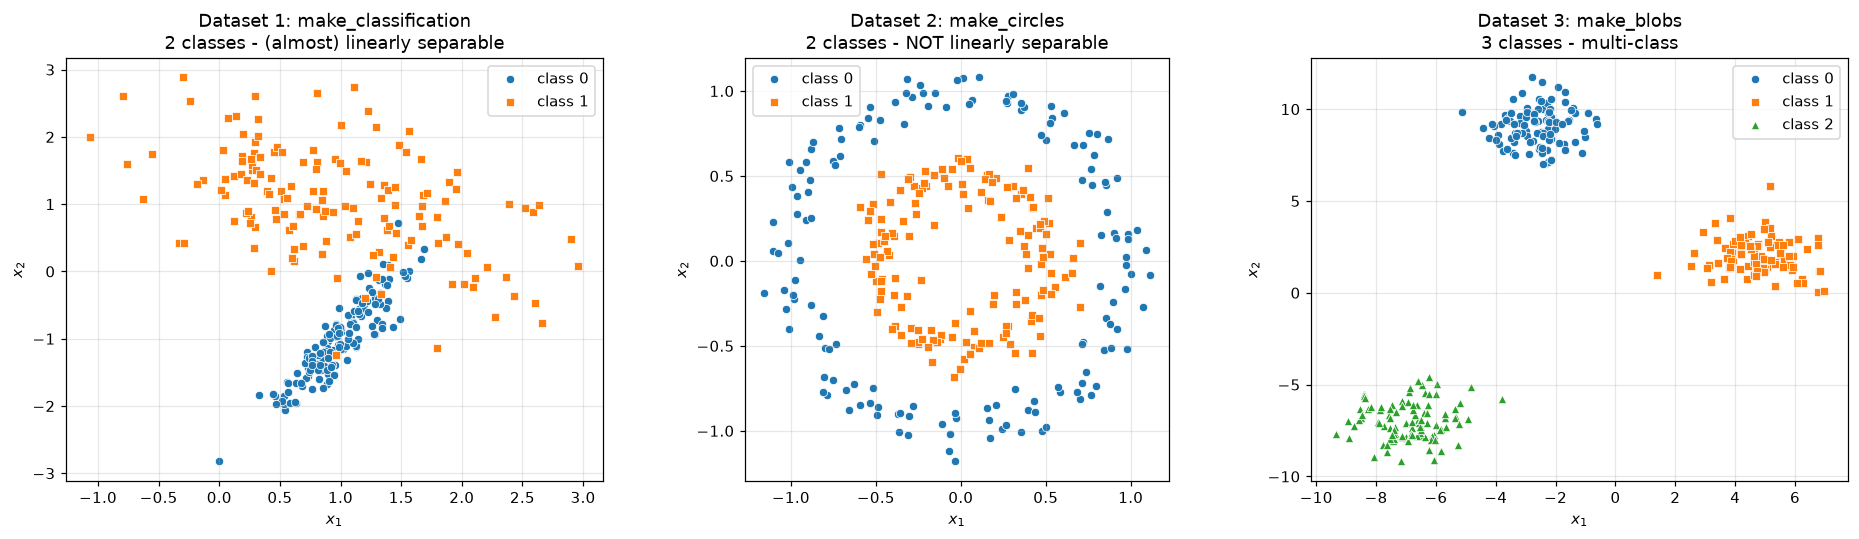

In [3]:
CLASS_STYLE = [("tab:blue", "o"), ("tab:orange", "s"), ("tab:green", "^")]

def plot_dataset(x, y, title, ax=None):
    """Scatter plot of a 2-D dataset, one color/marker per class."""
    ax = ax or plt.gca()
    for label in np.unique(y):
        color, marker = CLASS_STYLE[label]
        ax.scatter(x[y == label, 0], x[y == label, 1], c=color, marker=marker,
                   edgecolors="white", linewidths=0.5, s=30, label=f"class {label}")
    ax.set_title(title)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.legend()

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (title, (x, y)) in zip(axes, datasets.items()):
    plot_dataset(x, y, title, ax)
axes[1].set_aspect("equal")   # keep the circles round
plt.tight_layout()
plt.savefig("figures/stage1_datasets.png", dpi=150, bbox_inches="tight")
plt.show()

### Stage 1.3 — Stratified train/test split (80% / 20%)
The same split (`random_state=42`) is used in every experiment. Test data is used only for final evaluation.

In [4]:
x1_train, x1_test, y1_train, y1_test = train_test_split(
    x1, y1, test_size=TEST_SIZE, stratify=y1, random_state=SPLIT_SEED)
x2_train, x2_test, y2_train, y2_test = train_test_split(
    x2, y2, test_size=TEST_SIZE, stratify=y2, random_state=SPLIT_SEED)
x3_train, x3_test, y3_train, y3_test = train_test_split(
    x3, y3, test_size=TEST_SIZE, stratify=y3, random_state=SPLIT_SEED)

# Short summary: sizes and class counts of each split
split_labels = {1: (y1_train, y1_test), 2: (y2_train, y2_test), 3: (y3_train, y3_test)}
print(f"{'Dataset':<10}{'Train':<8}{'Test':<8}{'Train class counts':<22}{'Test class counts'}")
for dataset_id, (y_train, y_test) in split_labels.items():
    print(f"{dataset_id:<10}{len(y_train):<8}{len(y_test):<8}{str(np.bincount(y_train)):<22}{np.bincount(y_test)}")

Dataset   Train   Test    Train class counts    Test class counts
1         240     60      [120 120]             [30 30]
2         240     60      [120 120]             [30 30]
3         240     60      [80 80 80]            [20 20 20]


## Stage 2 — Single Neuron (Perceptron)
A single neuron with the bias implemented as a constant input of $-1$: $\tilde{x} = [x_1, x_2, -1]$, $net = w^\top \tilde{x}$.
Its decision boundary is the line $w_1 x_1 + w_2 x_2 - w_0 = 0$. Two learning rules are compared:

| Mode | Activation | Update (online) | Error curve |
|---|---|---|---|
| (a) Error-correction | step: $y = 1$ if $net \ge 0$ else $0$ | $w \leftarrow w + \eta\,(d - y)\,\tilde{x}$ | misclassification count |
| (b) Generalized delta | sigmoid | $w \leftarrow w + \eta\,(d - y)\,y(1-y)\,\tilde{x}$ | SSE $E = \tfrac12\sum (d-y)^2$ |

**Training mode (used in every stage):** online learning, i.e. one weight update per sample, with the sample order reshuffled every epoch using the experiment's own `np.random.default_rng(seed)`.
Settings: $\eta = 0.1$, initial weights $\sim U[-0.5, 0.5]$, seed 0, **fixed cap of 200 epochs** (zero error is not used as a stopping rule). The error is measured on the whole training set after each epoch.

### Stage 2.1 — Implementation

In [5]:
def add_bias(x):
    """Append the constant bias input -1 to every sample: [x1, x2] -> [x1, x2, -1]."""
    return np.hstack([x, -np.ones((x.shape[0], 1))])


def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


def plot_decision_boundary(predict_fn, x, y, title, ax=None, margin=0.5, resolution=300):
    """Color the plane by predict_fn's class labels, then overlay the data points."""
    ax = ax or plt.gca()
    x1_min, x1_max = x[:, 0].min() - margin, x[:, 0].max() + margin
    x2_min, x2_max = x[:, 1].min() - margin, x[:, 1].max() + margin
    grid_x1, grid_x2 = np.meshgrid(np.linspace(x1_min, x1_max, resolution),
                                   np.linspace(x2_min, x2_max, resolution))
    grid_labels = predict_fn(np.c_[grid_x1.ravel(), grid_x2.ravel()]).reshape(grid_x1.shape)
    n_classes = max(len(np.unique(y)), 2)
    cmap = ListedColormap([CLASS_STYLE[label][0] for label in range(n_classes)])
    ax.contourf(grid_x1, grid_x2, grid_labels, levels=np.arange(n_classes + 1) - 0.5, cmap=cmap, alpha=0.25)
    ax.contour(grid_x1, grid_x2, grid_labels, levels=np.arange(n_classes) + 0.5, colors="k", linewidths=0.8)
    plot_dataset(x, y, title, ax)


class Perceptron:
    """Single neuron. mode='step': error-correction rule; mode='sigmoid': generalized delta rule (SSE)."""

    def __init__(self, mode, eta=0.1, seed=0):
        self.mode, self.eta = mode, eta
        self.rng = np.random.default_rng(seed)
        self.weights = self.rng.uniform(-0.5, 0.5, 3)          # [w1, w2, w0]

    def output(self, x):
        net = add_bias(x) @ self.weights
        return (net >= 0).astype(float) if self.mode == "step" else sigmoid(net)

    def predict(self, x):
        return (self.output(x) >= 0.5).astype(int)

    def error(self, x, y):
        """Misclassification count (step) or SSE cost (sigmoid) over a whole set."""
        if self.mode == "step":
            return int(np.sum(self.predict(x) != y))
        return 0.5 * np.sum((y - self.output(x)) ** 2)

    def fit(self, x, y, epochs=200):
        x_bias = add_bias(x)
        self.history = []
        for _ in range(epochs):
            for i in self.rng.permutation(len(x)):      # online updates, reshuffled each epoch
                net = x_bias[i] @ self.weights
                if self.mode == "step":
                    output = float(net >= 0)
                    self.weights += self.eta * (y[i] - output) * x_bias[i]
                else:
                    output = sigmoid(net)
                    self.weights += self.eta * (y[i] - output) * output * (1 - output) * x_bias[i]
            self.history.append(self.error(x, y))
        return self

### Stage 2.2 — Experiment: both rules on datasets 1 and 2

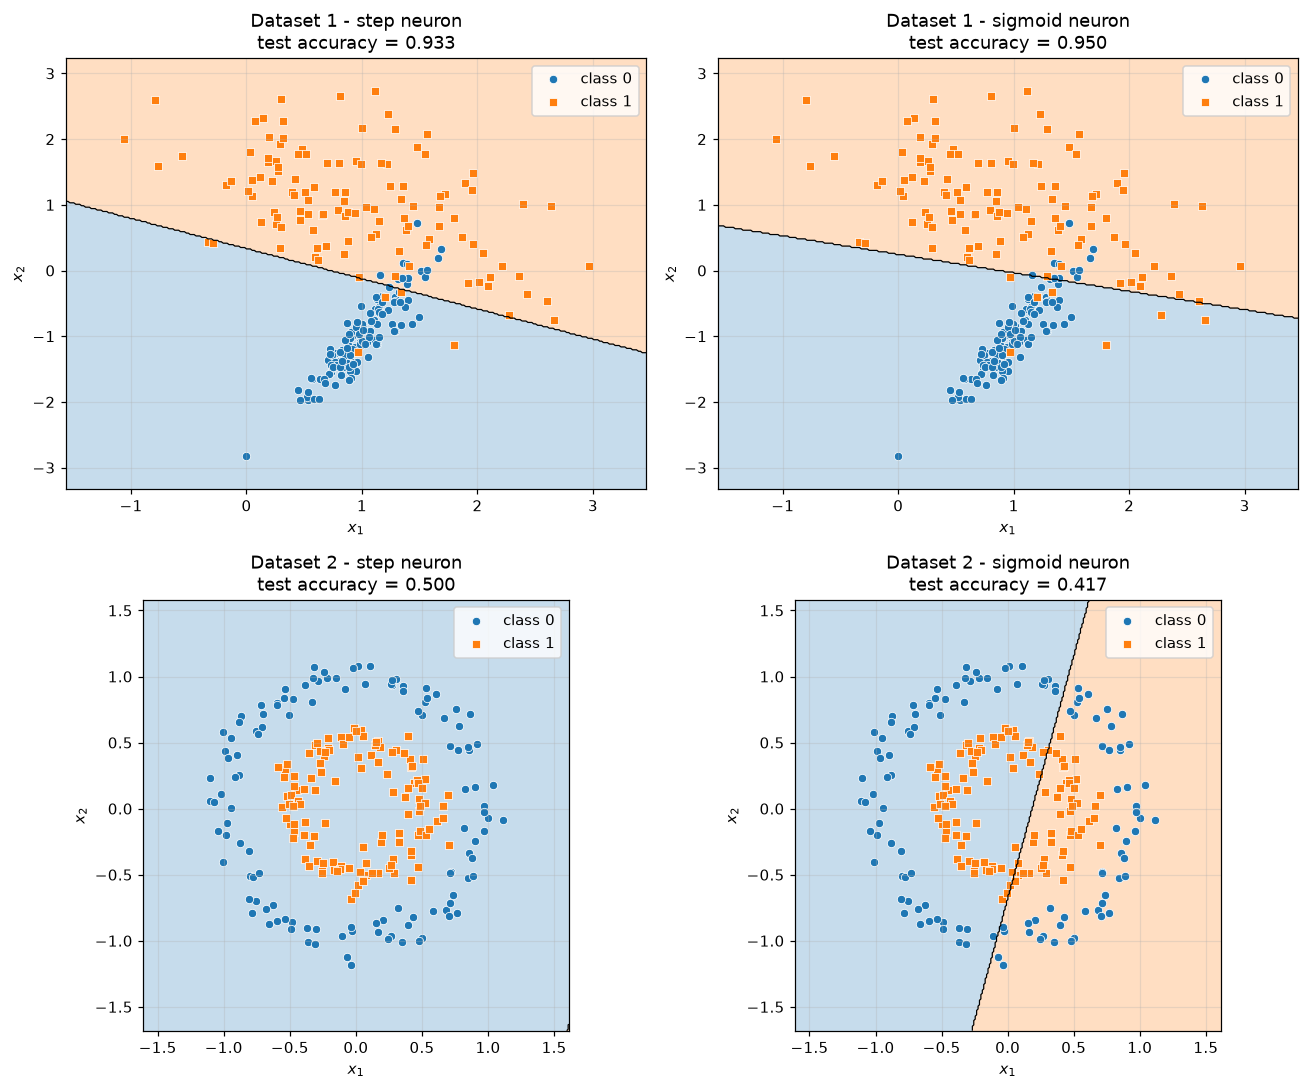

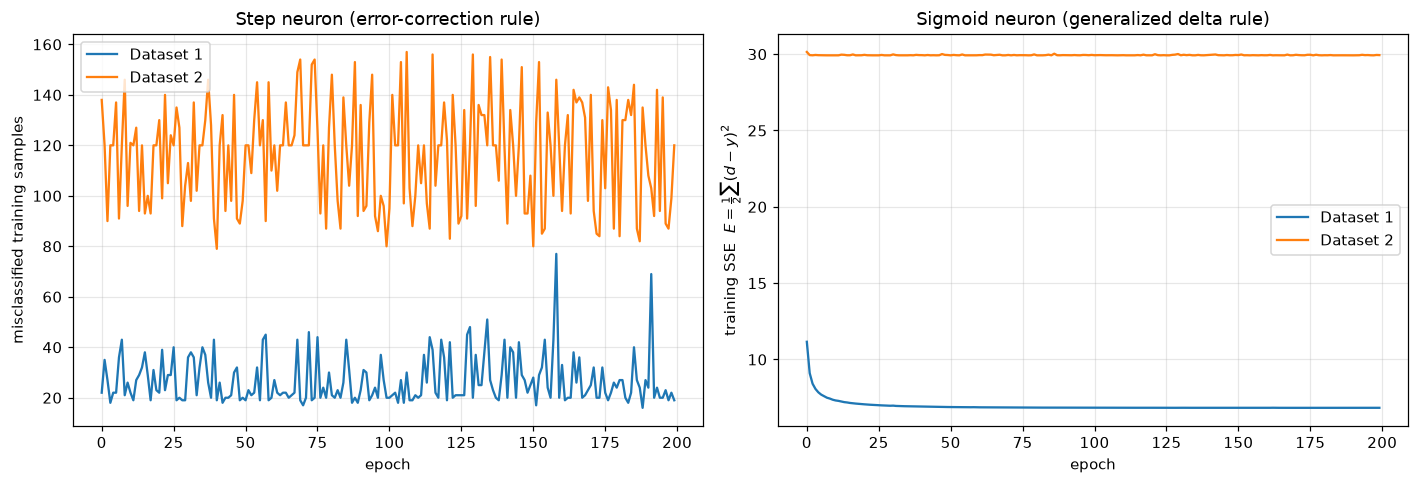

In [6]:
PERCEPTRON_EPOCHS, PERCEPTRON_ETA, PERCEPTRON_SEED = 200, 0.1, 0
binary_datasets = {1: (x1_train, x1_test, y1_train, y1_test),
                   2: (x2_train, x2_test, y2_train, y2_test)}

perceptrons = {}
for dataset_id, (x_train, x_test, y_train, y_test) in binary_datasets.items():
    for mode in ("step", "sigmoid"):
        perceptrons[(dataset_id, mode)] = Perceptron(mode, PERCEPTRON_ETA, PERCEPTRON_SEED).fit(
            x_train, y_train, PERCEPTRON_EPOCHS)

# Decision boundaries (training points shown, test accuracy in the title)
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for row, (dataset_id, (x_train, x_test, y_train, y_test)) in enumerate(binary_datasets.items()):
    for col, mode in enumerate(("step", "sigmoid")):
        perceptron = perceptrons[(dataset_id, mode)]
        test_acc = accuracy_score(y_test, perceptron.predict(x_test))
        plot_decision_boundary(perceptron.predict, x_train, y_train,
                               f"Dataset {dataset_id} - {mode} neuron\ntest accuracy = {test_acc:.3f}", axes[row, col])
for ax in axes[1]:
    ax.set_aspect("equal")
plt.tight_layout()
plt.savefig("figures/stage2_boundaries.png", dpi=150, bbox_inches="tight")
plt.show()

# Error curves per epoch
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for dataset_id in binary_datasets:
    axes[0].plot(perceptrons[(dataset_id, "step")].history, label=f"Dataset {dataset_id}")
    axes[1].plot(perceptrons[(dataset_id, "sigmoid")].history, label=f"Dataset {dataset_id}")
axes[0].set(title="Step neuron (error-correction rule)", xlabel="epoch", ylabel="misclassified training samples")
axes[1].set(title="Sigmoid neuron (generalized delta rule)", xlabel="epoch", ylabel="training SSE  $E=\\frac{1}{2}\\sum(d-y)^2$")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.savefig("figures/stage2_error_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### Stage 2.3 — Results

In [7]:
print(f"{'Dataset':<9}{'Rule':<10}{'final error':>12}{'best error':>12}{'train acc':>11}{'test acc':>10}   weights [w1, w2, w0]")
for (dataset_id, mode), perceptron in perceptrons.items():
    x_train, x_test, y_train, y_test = binary_datasets[dataset_id]
    number_format = "{:>12d}" if mode == "step" else "{:>12.2f}"
    train_acc = accuracy_score(y_train, perceptron.predict(x_train))
    test_acc = accuracy_score(y_test, perceptron.predict(x_test))
    print(f"{dataset_id:<9}{mode:<10}" + number_format.format(perceptron.history[-1])
          + number_format.format(min(perceptron.history))
          + f"{train_acc:>11.3f}{test_acc:>10.3f}   {np.round(perceptron.weights, 3)}")

Dataset  Rule       final error  best error  train acc  test acc   weights [w1, w2, w0]
1        step                19          16      0.921     0.933   [0.194 0.423 0.141]
1        sigmoid           6.83        6.83      0.925     0.950   [1.181 4.203 1.034]
2        step               120          79      0.500     0.500   [ 0.069 -0.019  0.141]
2        sigmoid          29.94       29.92      0.479     0.417   [ 0.203 -0.055  0.038]


**Interpretation:** see Stage 2 in `report/report.md` (why one neuron fails on dataset 2 and the link to XOR).

## Stage 3 — MLP Implementation (one hidden layer)
Architecture: inputs $\to$ hidden layer (sigmoid) $\to$ output layer (sigmoid). Bias is the constant input $-1$ appended to the input vector and to the hidden-layer output, so
$W_1 \in \mathbb{R}^{n_h \times (n_{in}+1)}$ and $W_2 \in \mathbb{R}^{n_{out} \times (n_h+1)}$ (last column = bias weights).

- Forward: $h = \sigma(W_1 \tilde{x})$, $\;y = \sigma(W_2 \tilde{h})$
- Loss: $E = \tfrac12 \sum (d - y)^2$
- Error signals: $\delta_o = (d - y)\,y(1-y)$, $\;\delta_h = h(1-h) \odot (W_2[:, :-1]^\top \delta_o)$
- Update (descent direction): $W_2 \mathrel{+}= \eta\,\delta_o \tilde{h}^\top$, $\;W_1 \mathrel{+}= \eta\,\delta_h \tilde{x}^\top$, i.e. $\partial E/\partial W = -\delta\,\tilde{\text{input}}^\top$

Training is online (per-sample updates, reshuffled every epoch). The `output_type="softmax"` option is only used in the Bonus (Softmax + Cross-Entropy, where $\delta_o = d - y$).

### Stage 3.1 — Implementation

In [8]:
def softmax(z):
    exp_z = np.exp(z - z.max(axis=1, keepdims=True))
    return exp_z / exp_z.sum(axis=1, keepdims=True)


def init_weights(n_inputs, n_hidden, n_outputs, scale, rng):
    """Uniform U[-scale, scale] init (scale=0 gives all-zero weights). Last column = bias weights."""
    W1 = rng.uniform(-scale, scale, (n_hidden, n_inputs + 1))
    W2 = rng.uniform(-scale, scale, (n_outputs, n_hidden + 1))
    return W1, W2


def forward(W1, W2, x, output_type="sigmoid"):
    """Feedforward for a batch x (n, n_inputs). Returns the biased input, hidden output,
    biased hidden output and network output."""
    x_bias = add_bias(x)
    hidden = sigmoid(x_bias @ W1.T)
    hidden_bias = add_bias(hidden)
    net_output = hidden_bias @ W2.T
    output = softmax(net_output) if output_type == "softmax" else sigmoid(net_output)
    return x_bias, hidden, hidden_bias, output


def backward(W2, hidden, output, targets, output_type="sigmoid"):
    """Error signals of the output and hidden layers (bias column of W2 excluded)."""
    if output_type == "softmax":
        delta_output = targets - output
    else:
        delta_output = (targets - output) * output * (1 - output)
    delta_hidden = hidden * (1 - hidden) * (delta_output @ W2[:, :-1])
    return delta_output, delta_hidden


def update(W1, W2, x_bias, hidden_bias, delta_output, delta_hidden, eta):
    """In-place weight update w += eta * delta * input (sums over the rows of a batch)."""
    W2 += eta * delta_output.T @ hidden_bias
    W1 += eta * delta_hidden.T @ x_bias


def cost(targets, output, output_type="sigmoid"):
    """SSE with 1/2 (sigmoid output) or cross-entropy (softmax output), summed over the set."""
    if output_type == "softmax":
        return -np.sum(targets * np.log(output + 1e-12))
    return 0.5 * np.sum((targets - output) ** 2)


def to_targets(y, n_outputs):
    """Column of 0/1 targets for one output, one-hot rows for several outputs."""
    return y.reshape(-1, 1).astype(float) if n_outputs == 1 else np.eye(n_outputs)[y]


def predict_mlp(W1, W2, x, output_type="sigmoid"):
    output = forward(W1, W2, x, output_type)[3]
    return (output[:, 0] >= 0.5).astype(int) if output.shape[1] == 1 else output.argmax(axis=1)


def train_mlp(x, y, n_hidden=4, eta=0.1, epochs=300, scale=1.0, seed=0, n_outputs=1, output_type="sigmoid"):
    """Online backprop training. Returns the weights and the per-epoch training cost and accuracy."""
    rng = np.random.default_rng(seed)
    targets = to_targets(y, n_outputs)
    W1, W2 = init_weights(x.shape[1], n_hidden, n_outputs, scale, rng)
    cost_history, acc_history = [], []
    for _ in range(epochs):
        for i in rng.permutation(len(x)):
            x_bias, hidden, hidden_bias, output = forward(W1, W2, x[i:i + 1], output_type)
            delta_output, delta_hidden = backward(W2, hidden, output, targets[i:i + 1], output_type)
            update(W1, W2, x_bias, hidden_bias, delta_output, delta_hidden, eta)
        cost_history.append(cost(targets, forward(W1, W2, x, output_type)[3], output_type))
        acc_history.append(np.mean(predict_mlp(W1, W2, x, output_type) == y))
    return W1, W2, np.array(cost_history), np.array(acc_history)

### Stage 3.2 — Verification A: one backprop step by hand (2-2-1 network)
One sample $x = [1.0,\ 0.5]$ with target $d = 1$, learning rate $\eta = 0.5$ and hand-picked weights
(columns are the weights of $x_1$, $x_2$ and the bias input $-1$):
$W_1 = \begin{bmatrix} 0.2 & -0.3 & 0.4 \\ 0.5 & 0.1 & -0.2 \end{bmatrix}$, $\;W_2 = \begin{bmatrix} 0.3 & -0.4 & 0.1 \end{bmatrix}$.
Every intermediate value is printed so it can be matched against the hand calculation in the report.

In [9]:
np.set_printoptions(precision=6, suppress=True)
x_sample = np.array([[1.0, 0.5]])
d_sample = np.array([[1.0]])
eta_sample = 0.5
W1_hand = np.array([[0.2, -0.3, 0.4],
                    [0.5, 0.1, -0.2]])
W2_hand = np.array([[0.3, -0.4, 0.1]])

x_bias, hidden, hidden_bias, output = forward(W1_hand, W2_hand, x_sample)
delta_output, delta_hidden = backward(W2_hand, hidden, output, d_sample)
W1_new, W2_new = W1_hand.copy(), W2_hand.copy()
update(W1_new, W2_new, x_bias, hidden_bias, delta_output, delta_hidden, eta_sample)
output_after = forward(W1_new, W2_new, x_sample)[3]

print("x~ (with bias)     :", x_bias[0])
print("net_h = W1 x~      :", (x_bias @ W1_hand.T)[0])
print("h = sigmoid(net_h) :", hidden[0])
print("h~ (with bias)     :", hidden_bias[0])
print("net_o = W2 h~      :", (hidden_bias @ W2_hand.T)[0])
print("y = sigmoid(net_o) :", output[0])
print("E = 0.5 (d - y)^2  :", cost(d_sample, output))
print("delta_o            :", delta_output[0])
print("delta_h            :", delta_hidden[0])
print("dE/dW2 = -delta_o h~ :", -(delta_output.T @ hidden_bias)[0])
print("dE/dW1 = -delta_h x~ :\n", -(delta_hidden.T @ x_bias))
print("new W2 :", W2_new[0])
print("new W1 :\n", W1_new)
print("output after the update:", output_after[0], "(target 1, error decreased:",
      cost(d_sample, output_after) < cost(d_sample, output), ")")
np.set_printoptions()

x~ (with bias)     : [ 1.   0.5 -1. ]
net_h = W1 x~      : [-0.35  0.75]
h = sigmoid(net_h) : [0.413382 0.679179]
h~ (with bias)     : [ 0.413382  0.679179 -1.      ]
net_o = W2 h~      : [-0.247657]
y = sigmoid(net_o) : [0.4384]
E = 0.5 (d - y)^2  : 0.15769709143815383
delta_o            : [0.138269]
delta_h            : [ 0.010059 -0.012051]
dE/dW2 = -delta_o h~ : [-0.057158 -0.093909  0.138269]
dE/dW1 = -delta_h x~ :
 [[-0.010059 -0.005029  0.010059]
 [ 0.012051  0.006026 -0.012051]]
new W2 : [ 0.328579 -0.353045  0.030866]
new W1 :
 [[ 0.205029 -0.297485  0.394971]
 [ 0.493974  0.096987 -0.193974]]
output after the update: [0.466831] (target 1, error decreased: True )


### Stage 3.3 — Verification B: gradient checking
Backprop gradient $g_{bp} = \partial E/\partial W = -\delta\,\tilde{\text{input}}^\top$ is compared with the central difference
$g_{num} = \dfrac{E(w+\varepsilon) - E(w-\varepsilon)}{2\varepsilon}$ with $\varepsilon = 10^{-5}$, for every single weight.
This is done before any update and without momentum. Relative error: $\dfrac{\lVert g_{bp} - g_{num}\rVert}{\lVert g_{bp}\rVert + \lVert g_{num}\rVert}$.

In [10]:
GRADCHECK_EPS = 1e-5


def backprop_gradients(W1, W2, x, targets, output_type="sigmoid"):
    x_bias, hidden, hidden_bias, output = forward(W1, W2, x, output_type)
    delta_output, delta_hidden = backward(W2, hidden, output, targets, output_type)
    return -(delta_hidden.T @ x_bias), -(delta_output.T @ hidden_bias)


def numerical_gradients(W1, W2, x, targets, output_type="sigmoid", eps=GRADCHECK_EPS):
    gradients = []
    for W in (W1, W2):
        gradient = np.zeros_like(W)
        for index in np.ndindex(W.shape):
            original = W[index]
            W[index] = original + eps
            cost_plus = cost(targets, forward(W1, W2, x, output_type)[3], output_type)
            W[index] = original - eps
            cost_minus = cost(targets, forward(W1, W2, x, output_type)[3], output_type)
            W[index] = original
            gradient[index] = (cost_plus - cost_minus) / (2 * eps)
        gradients.append(gradient)
    return gradients


def relative_error(a, b):
    return np.linalg.norm(a - b) / (np.linalg.norm(a) + np.linalg.norm(b))


gradcheck_rng = np.random.default_rng(0)
gradcheck_cases = {
    "2-2-1 hand network, 1 sample": (W1_hand.copy(), W2_hand.copy(), x_sample, d_sample, "sigmoid"),
    "2-4-1 U[-1,1], 10 samples of dataset 2": (*init_weights(2, 4, 1, 1.0, gradcheck_rng),
                                               x2_train[:10], to_targets(y2_train[:10], 1), "sigmoid"),
    "2-4-3 U[-1,1], 10 samples of dataset 3": (*init_weights(2, 4, 3, 1.0, gradcheck_rng),
                                               x3_train[:10], to_targets(y3_train[:10], 3), "sigmoid"),
    "2-4-3 softmax + CE (Bonus b)": (*init_weights(2, 4, 3, 1.0, gradcheck_rng),
                                     x3_train[:10], to_targets(y3_train[:10], 3), "softmax"),
}
print(f"eps = {GRADCHECK_EPS}")
print(f"{'Case':<42}{'rel.err W1':>12}{'rel.err W2':>12}{'rel.err all':>13}")
for case_name, (W1, W2, x, targets, output_type) in gradcheck_cases.items():
    grad_backprop = backprop_gradients(W1, W2, x, targets, output_type)
    grad_numerical = numerical_gradients(W1, W2, x, targets, output_type)
    all_backprop = np.concatenate([g.ravel() for g in grad_backprop])
    all_numerical = np.concatenate([g.ravel() for g in grad_numerical])
    print(f"{case_name:<42}{relative_error(grad_backprop[0], grad_numerical[0]):>12.2e}"
          f"{relative_error(grad_backprop[1], grad_numerical[1]):>12.2e}"
          f"{relative_error(all_backprop, all_numerical):>13.2e}")

eps = 1e-05
Case                                        rel.err W1  rel.err W2  rel.err all
2-2-1 hand network, 1 sample                  1.78e-10    8.18e-12     2.48e-11
2-4-1 U[-1,1], 10 samples of dataset 2        1.28e-10    8.17e-12     2.68e-11
2-4-3 U[-1,1], 10 samples of dataset 3        2.18e-10    2.46e-11     5.87e-11
2-4-3 softmax + CE (Bonus b)                  6.19e-11    2.67e-11     4.30e-11


### Stage 3.4 — Baseline MLP on dataset 2
The spec does not fix the initialization of the baseline, so a **small uniform range $U[-1, 1]$** is used.
This configuration is the reference for every experiment in Stage 4.

Baseline configuration (reference for Stage 4)
  architecture  : 2 - 4 - 1 (sigmoid hidden, sigmoid output)
  bias          : constant input -1
  loss          : SSE, E = 0.5 * sum (d - y)^2
  training      : online, reshuffle every epoch
  learning rate : 0.1
  epochs        : 300
  init          : U[-1, 1]
  seed          : 0
  prediction    : y >= 0.5 -> class 1


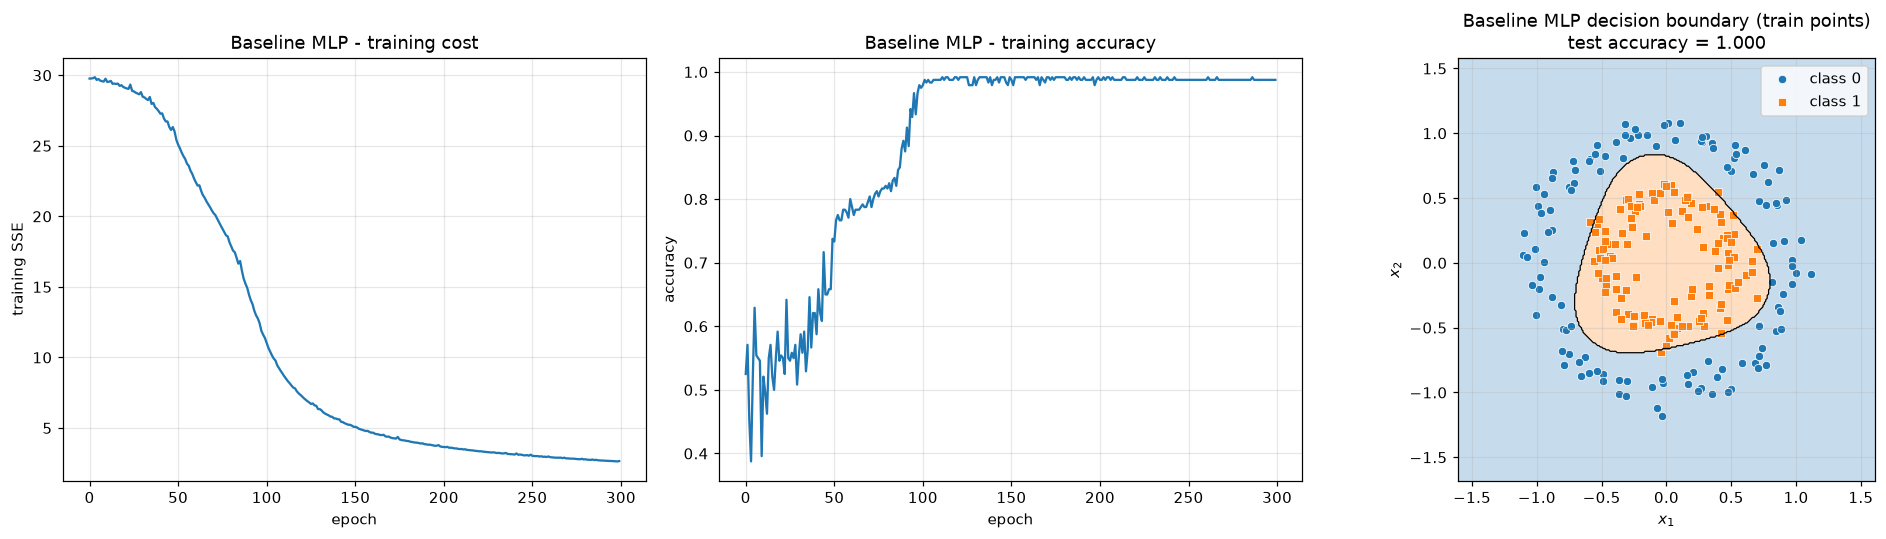

In [11]:
BASELINE = dict(n_hidden=4, eta=0.1, epochs=300, scale=1.0, seed=0)


def run_mlp(**changes):
    """Train the baseline MLP on dataset 2 with some settings changed; evaluate it on the test split."""
    config = {**BASELINE, **changes}
    W1, W2, cost_history, acc_history = train_mlp(x2_train, y2_train, **config)
    return dict(config=config, W1=W1, W2=W2, costs=cost_history, accs=acc_history,
                train_acc=acc_history[-1], test_acc=accuracy_score(y2_test, predict_mlp(W1, W2, x2_test)))


print("Baseline configuration (reference for Stage 4)")
for setting, value in [("architecture", "2 - 4 - 1 (sigmoid hidden, sigmoid output)"),
                       ("bias", "constant input -1"), ("loss", "SSE, E = 0.5 * sum (d - y)^2"),
                       ("training", "online, reshuffle every epoch"), ("learning rate", BASELINE["eta"]),
                       ("epochs", BASELINE["epochs"]), ("init", "U[-1, 1]"), ("seed", BASELINE["seed"]),
                       ("prediction", "y >= 0.5 -> class 1")]:
    print(f"  {setting:<14}: {value}")

baseline_run = run_mlp()
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(baseline_run["costs"])
axes[0].set(title="Baseline MLP - training cost", xlabel="epoch", ylabel="training SSE")
axes[1].plot(baseline_run["accs"])
axes[1].set(title="Baseline MLP - training accuracy", xlabel="epoch", ylabel="accuracy")
plot_decision_boundary(lambda grid: predict_mlp(baseline_run["W1"], baseline_run["W2"], grid), x2_train, y2_train,
                       f"Baseline MLP decision boundary (train points)\ntest accuracy = {baseline_run['test_acc']:.3f}",
                       axes[2])
axes[2].set_aspect("equal")
plt.tight_layout()
plt.savefig("figures/stage3_baseline.png", dpi=150, bbox_inches="tight")
plt.show()

### Stage 3.5 — Results

In [12]:
print(f"Final training SSE : {baseline_run['costs'][-1]:.4f}  (epoch 1: {baseline_run['costs'][0]:.4f})")
print(f"Train accuracy     : {baseline_run['train_acc']:.4f}")
print(f"Test accuracy      : {baseline_run['test_acc']:.4f}")
print("Test confusion matrix (rows = true, cols = predicted):\n",
      confusion_matrix(y2_test, predict_mlp(baseline_run["W1"], baseline_run["W2"], x2_test)))

Final training SSE : 2.6568  (epoch 1: 29.7641)
Train accuracy     : 0.9875
Test accuracy      : 1.0000
Test confusion matrix (rows = true, cols = predicted):
 [[30  0]
 [ 0 30]]


**Interpretation:** see Stage 3 in `report/report.md`.

## Stage 4 — Effect of Network Settings
Each experiment changes **one** factor of the Stage 3 baseline (4 hidden units, $\eta=0.1$, 300 epochs, $U[-1,1]$, seed 0),
keeps the data and split fixed, and retrains from scratch on dataset 2.

### Stage 4.1 — Weight initialization
Cases: (a) all zeros; (b) $U[-5, 5]$; (c) $U[-10, 10]$. The random cases (and the $U[-1,1]$ baseline for reference) are run with 5 seeds (0–4) and reported as mean ± std.
The column *saturated h at init* is the fraction of hidden activations with $h<0.05$ or $h>0.95$ on the training set **before** training (where $h(1-h)$, and therefore the gradient, is almost zero).

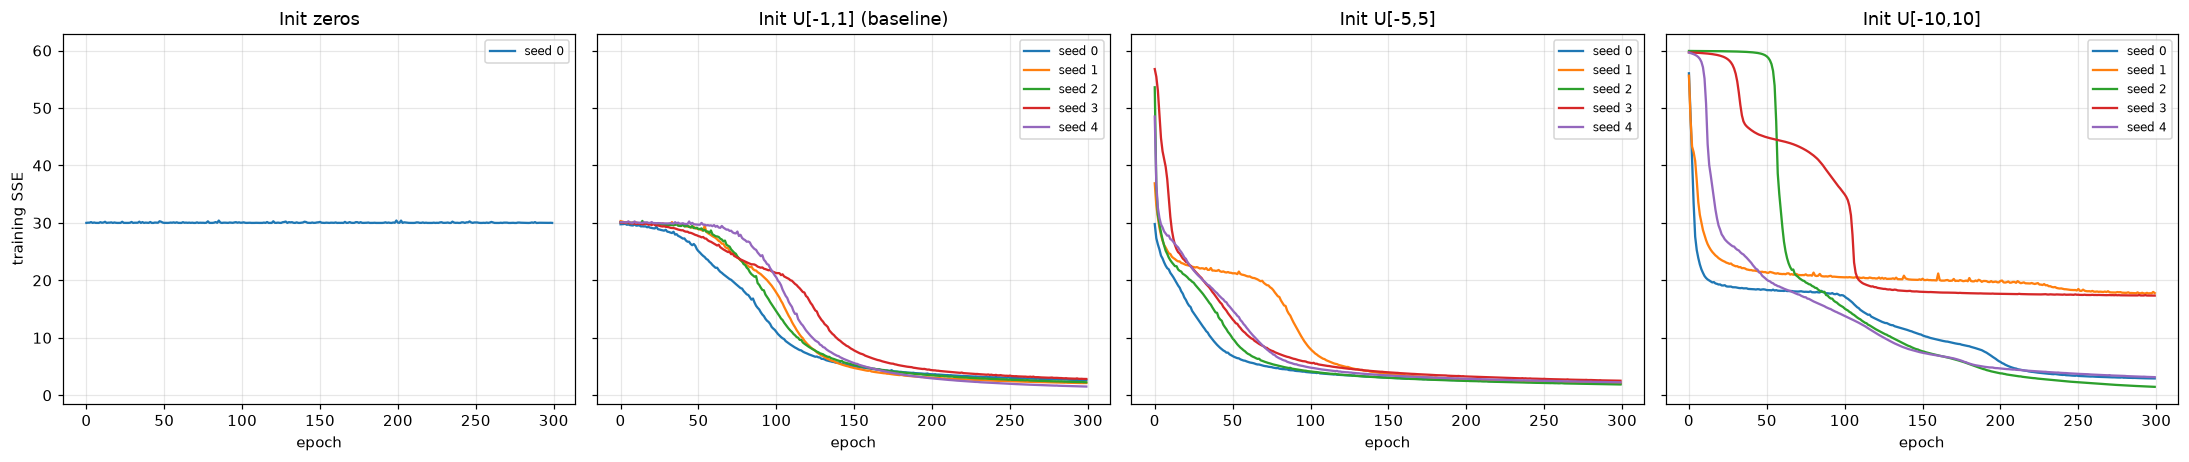

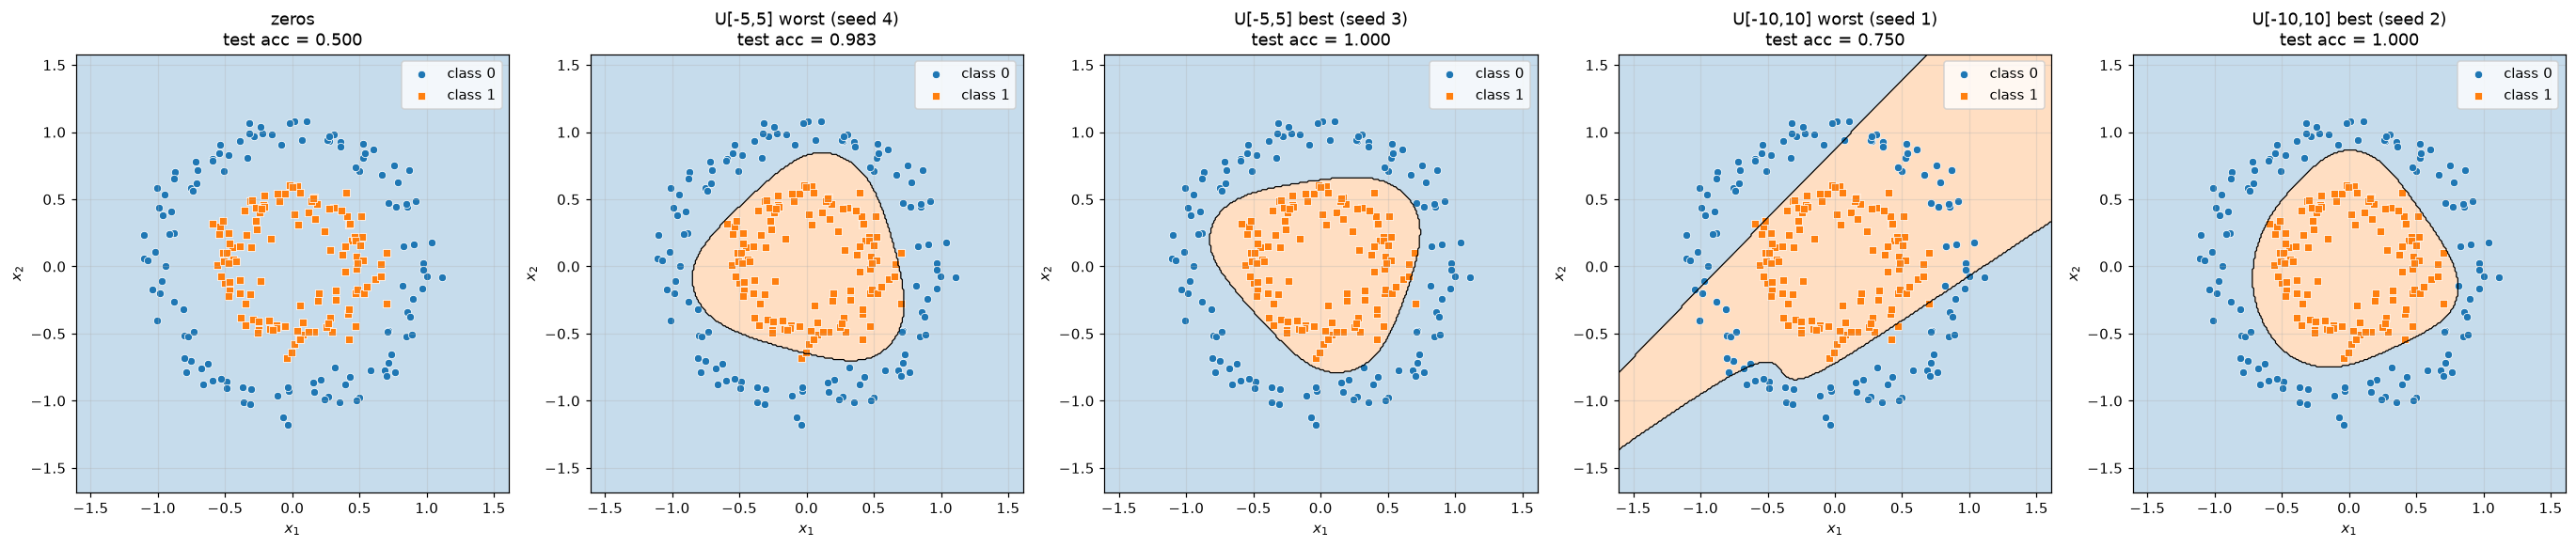

In [13]:
INIT_SEEDS = range(5)
init_scales = {"zeros": 0.0, "U[-1,1] (baseline)": 1.0, "U[-5,5]": 5.0, "U[-10,10]": 10.0}
init_runs = {}
for init_name, scale in init_scales.items():
    seeds = [0] if scale == 0 else INIT_SEEDS        # zero init is deterministic
    init_runs[init_name] = [run_mlp(scale=scale, seed=seed) for seed in seeds]


def saturation_at_init(scale, seed, x):
    """Fraction of saturated hidden activations for the initial weights used by train_mlp."""
    W1, _ = init_weights(2, BASELINE["n_hidden"], 1, scale, np.random.default_rng(seed))
    hidden = sigmoid(add_bias(x) @ W1.T)
    return np.mean((hidden < 0.05) | (hidden > 0.95))


fig, axes = plt.subplots(1, 4, figsize=(20, 4.3), sharey=True)
for ax, (init_name, runs) in zip(axes, init_runs.items()):
    for run in runs:
        ax.plot(run["costs"], label=f"seed {run['config']['seed']}")
    ax.set(title=f"Init {init_name}", xlabel="epoch")
    ax.legend(fontsize=8)
axes[0].set_ylabel("training SSE")
plt.tight_layout()
plt.savefig("figures/stage4_init_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# Boundaries: zero init, and the worst / best seed of each large random init
boundary_panels = [("zeros", init_runs["zeros"][0])]
for init_name in ("U[-5,5]", "U[-10,10]"):
    runs_by_acc = sorted(init_runs[init_name], key=lambda run: run["test_acc"])
    worst_run, best_run = runs_by_acc[0], runs_by_acc[-1]
    boundary_panels += [(f"{init_name} worst (seed {worst_run['config']['seed']})", worst_run),
                        (f"{init_name} best (seed {best_run['config']['seed']})", best_run)]
fig, axes = plt.subplots(1, 5, figsize=(25, 5))
for ax, (panel_title, run) in zip(axes, boundary_panels):
    plot_decision_boundary(lambda grid, run=run: predict_mlp(run["W1"], run["W2"], grid), x2_train, y2_train,
                           f"{panel_title}\ntest acc = {run['test_acc']:.3f}", ax)
    ax.set_aspect("equal")
plt.tight_layout()
plt.savefig("figures/stage4_init_boundaries.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
print(f"{'Init':<20}{'runs':>5}{'final train SSE':>22}{'train acc':>18}{'test acc':>18}{'saturated h at init':>22}")
for init_name, runs in init_runs.items():
    final_costs = np.array([run["costs"][-1] for run in runs])
    train_accs = np.array([run["train_acc"] for run in runs])
    test_accs = np.array([run["test_acc"] for run in runs])
    saturation = np.mean([saturation_at_init(run["config"]["scale"], run["config"]["seed"], x2_train) for run in runs])
    print(f"{init_name:<20}{len(runs):>5}{final_costs.mean():>13.3f} ± {final_costs.std():<6.3f}"
          f"{train_accs.mean():>10.3f} ± {train_accs.std():<5.3f}"
          f"{test_accs.mean():>10.3f} ± {test_accs.std():<5.3f}{saturation:>16.3f}")

print("\nPer-seed test accuracy:")
for init_name in ("U[-1,1] (baseline)", "U[-5,5]", "U[-10,10]"):
    print(f"  {init_name:<20}", [round(run["test_acc"], 3) for run in init_runs[init_name]])

zero_init_run = init_runs["zeros"][0]
np.set_printoptions(precision=5, suppress=True)
print("\nZero init - hidden weights W1 after training (rows = hidden units, cols = [w_x1, w_x2, w_bias]):\n",
      zero_init_run["W1"])
print("Zero init - output weights W2 after training ([w_h1..w_h4, w_bias]):\n", zero_init_run["W2"])
print("All hidden units identical:", np.allclose(zero_init_run["W1"], zero_init_run["W1"][0]))
np.set_printoptions()

Init                 runs       final train SSE         train acc          test acc   saturated h at init
zeros                   1       30.001 ± 0.000      0.500 ± 0.000     0.500 ± 0.000           0.000
U[-1,1] (baseline)      5        2.281 ± 0.459      0.993 ± 0.004     1.000 ± 0.000           0.000
U[-5,5]                 5        2.156 ± 0.222      0.993 ± 0.003     0.997 ± 0.007           0.452
U[-10,10]               5        8.538 ± 7.399      0.917 ± 0.080     0.890 ± 0.115           0.723

Per-seed test accuracy:
  U[-1,1] (baseline)   [1.0, 1.0, 1.0, 1.0, 1.0]
  U[-5,5]              [1.0, 1.0, 1.0, 1.0, 0.983]
  U[-10,10]            [0.983, 0.75, 1.0, 0.75, 0.967]

Zero init - hidden weights W1 after training (rows = hidden units, cols = [w_x1, w_x2, w_bias]):
 [[ 0.12762 -0.04627  0.57874]
 [ 0.12762 -0.04627  0.57874]
 [ 0.12762 -0.04627  0.57874]
 [ 0.12762 -0.04627  0.57874]]
Zero init - output weights W2 after training ([w_h1..w_h4, w_bias]):
 [[0.10436 0.10436 0.1043

**Interpretation:** see Stage 4.1 in `report/report.md`.

### Stage 4.2 — Learning rate
$\eta \in \{0.001, 0.01, 0.1, 1\}$, same 300 epochs and seed. *Cost increases* counts the epochs where the training cost went up (a measure of instability);
*epochs to SSE < 5* measures speed.

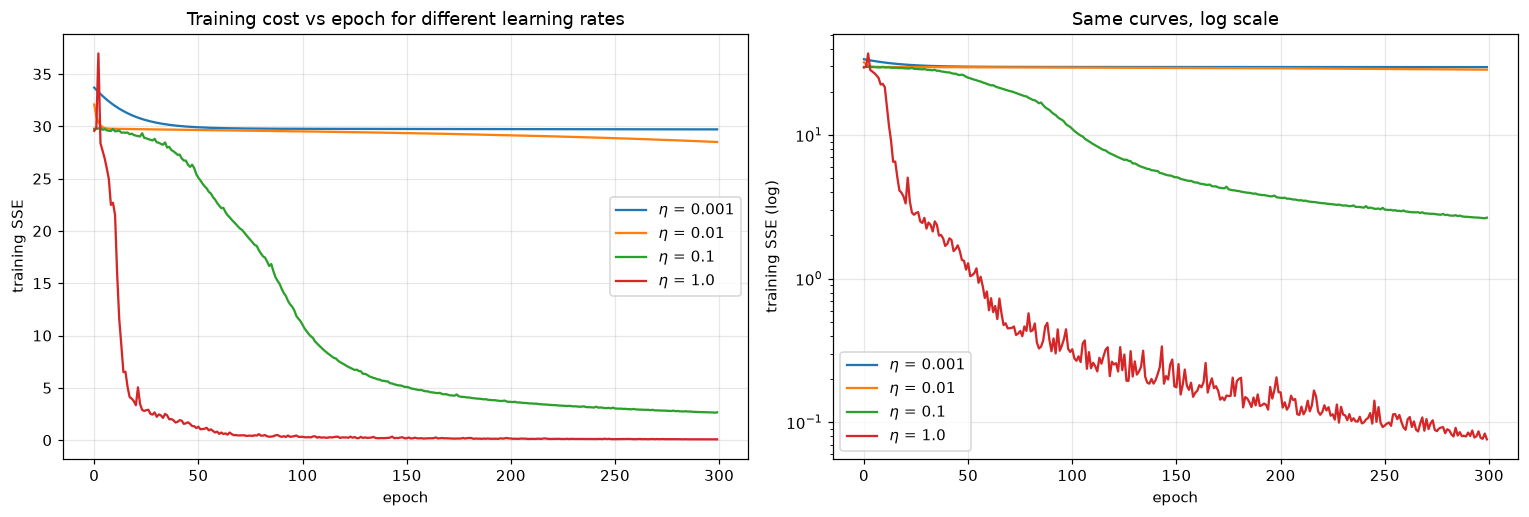

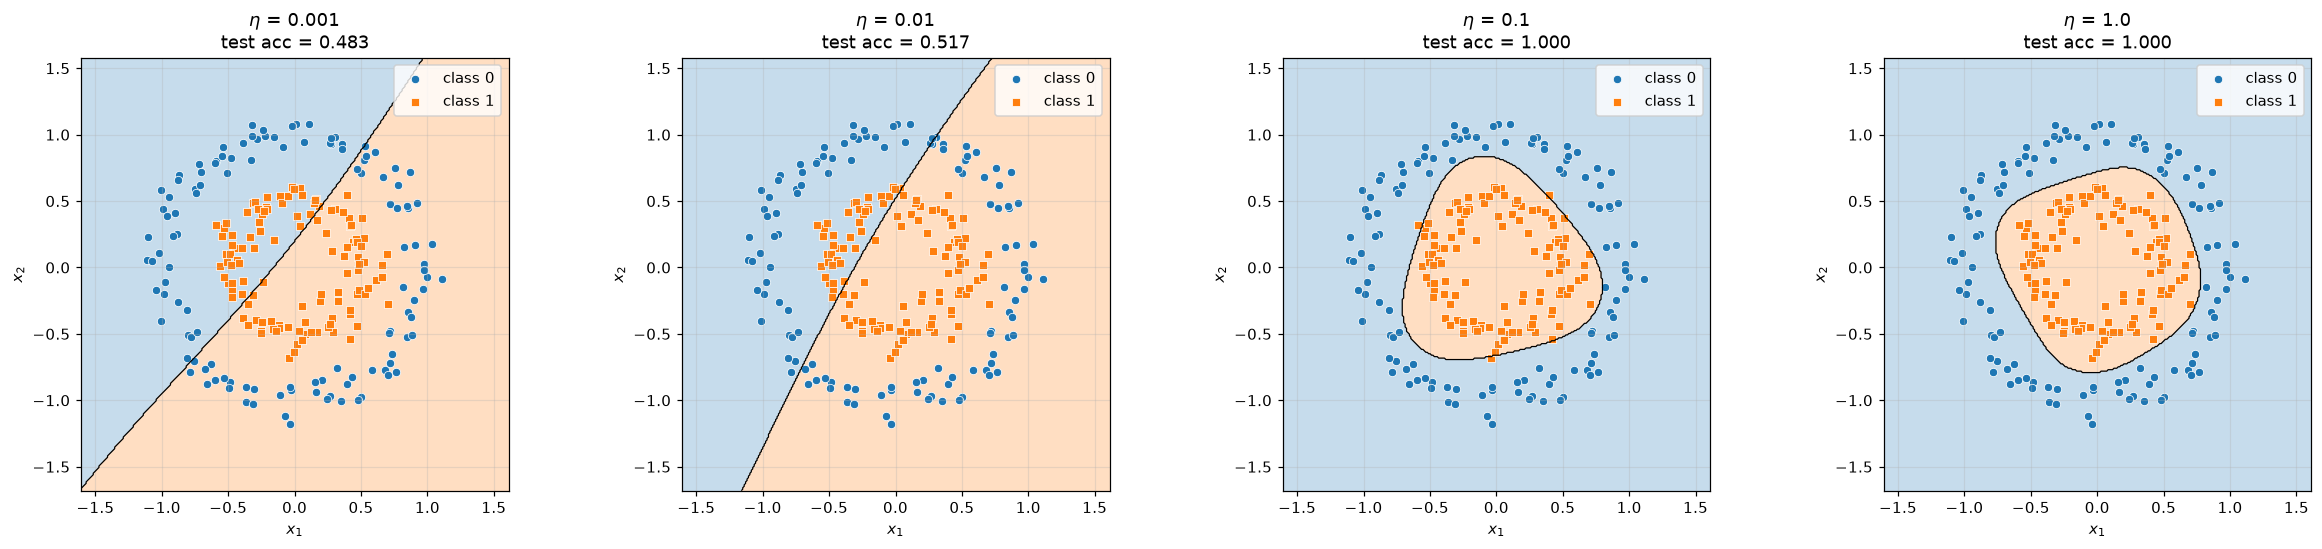

In [15]:
LEARNING_RATES = [0.001, 0.01, 0.1, 1.0]
learning_rate_runs = {eta: (baseline_run if eta == BASELINE["eta"] else run_mlp(eta=eta)) for eta in LEARNING_RATES}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for eta, run in learning_rate_runs.items():
    axes[0].plot(run["costs"], label=f"$\\eta$ = {eta}")
    axes[1].plot(run["costs"], label=f"$\\eta$ = {eta}")
axes[0].set(title="Training cost vs epoch for different learning rates", xlabel="epoch", ylabel="training SSE")
axes[1].set(title="Same curves, log scale", xlabel="epoch", ylabel="training SSE (log)", yscale="log")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.savefig("figures/stage4_lr_curves.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, (eta, run) in zip(axes, learning_rate_runs.items()):
    plot_decision_boundary(lambda grid, run=run: predict_mlp(run["W1"], run["W2"], grid), x2_train, y2_train,
                           f"$\\eta$ = {eta}\ntest acc = {run['test_acc']:.3f}", ax)
    ax.set_aspect("equal")
plt.tight_layout()
plt.savefig("figures/stage4_lr_boundaries.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
print(f"{'eta':<8}{'final SSE':>11}{'min SSE':>10}{'epochs to SSE<5':>17}{'cost increases':>16}{'train acc':>11}{'test acc':>10}")
for eta, run in learning_rate_runs.items():
    epochs_below_5 = np.where(run["costs"] < 5)[0]
    first_epoch_below_5 = str(epochs_below_5[0] + 1) if len(epochs_below_5) else "never"
    cost_increases = int(np.sum(np.diff(run["costs"]) > 0))
    print(f"{eta:<8}{run['costs'][-1]:>11.3f}{run['costs'].min():>10.3f}{first_epoch_below_5:>17}"
          f"{cost_increases:>16}{run['train_acc']:>11.3f}{run['test_acc']:>10.3f}")

eta       final SSE   min SSE  epochs to SSE<5  cost increases  train acc  test acc
0.001        29.708    29.708            never               0      0.517     0.483
0.01         28.502    28.502            never               0      0.550     0.517
0.1           2.657     2.632              153              56      0.988     1.000
1.0           0.076     0.076               18             147      1.000     1.000


**Interpretation:** see Stage 4.2 in `report/report.md`.

### Stage 4.3 — Number of hidden units
$n_h \in \{1, 2, 4, 8, 16\}$, everything else as in the baseline.

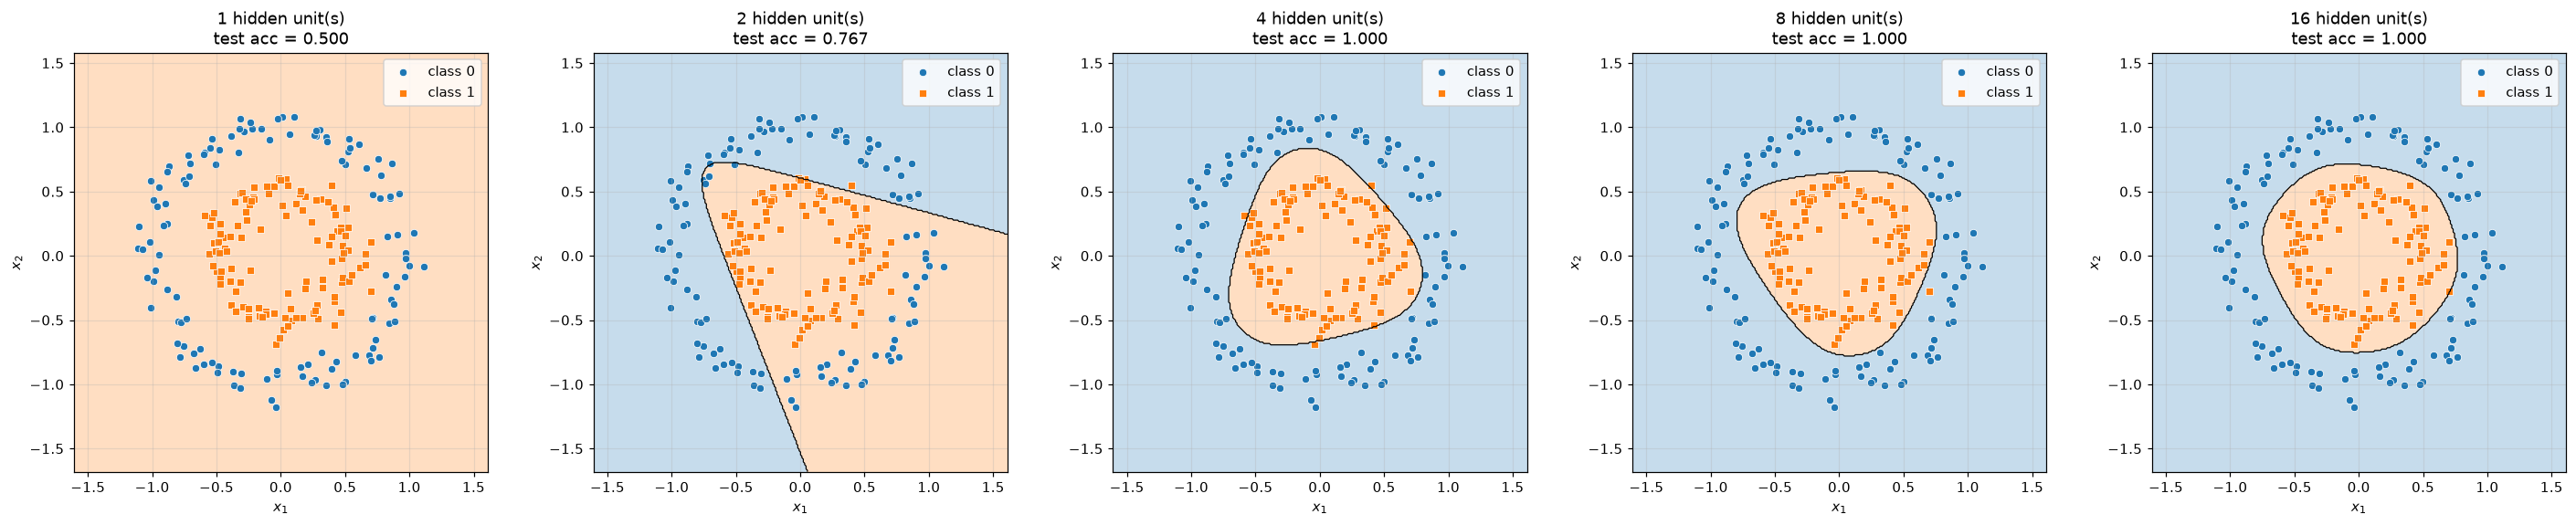

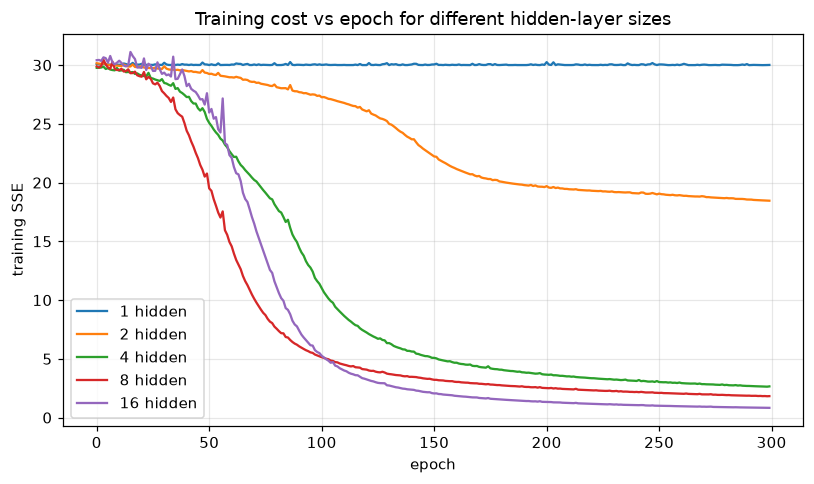

hidden   #weights  final SSE  train acc  test acc
1               5     30.010      0.500     0.500
2               9     18.457      0.817     0.767
4              17      2.657      0.988     1.000
8              33      1.827      0.996     1.000
16             65      0.831      1.000     1.000


In [17]:
HIDDEN_SIZES = [1, 2, 4, 8, 16]
hidden_runs = {n_hidden: (baseline_run if n_hidden == BASELINE["n_hidden"] else run_mlp(n_hidden=n_hidden))
               for n_hidden in HIDDEN_SIZES}

fig, axes = plt.subplots(1, 5, figsize=(26, 5))
for ax, (n_hidden, run) in zip(axes, hidden_runs.items()):
    plot_decision_boundary(lambda grid, run=run: predict_mlp(run["W1"], run["W2"], grid), x2_train, y2_train,
                           f"{n_hidden} hidden unit(s)\ntest acc = {run['test_acc']:.3f}", ax)
    ax.set_aspect("equal")
plt.tight_layout()
plt.savefig("figures/stage4_hidden_boundaries.png", dpi=150, bbox_inches="tight")
plt.show()

plt.figure(figsize=(7.5, 4.5))
for n_hidden, run in hidden_runs.items():
    plt.plot(run["costs"], label=f"{n_hidden} hidden")
plt.title("Training cost vs epoch for different hidden-layer sizes")
plt.xlabel("epoch")
plt.ylabel("training SSE")
plt.legend()
plt.tight_layout()
plt.savefig("figures/stage4_hidden_curves.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"{'hidden':<8}{'#weights':>9}{'final SSE':>11}{'train acc':>11}{'test acc':>10}")
for n_hidden, run in hidden_runs.items():
    n_weights = run["W1"].size + run["W2"].size
    print(f"{n_hidden:<8}{n_weights:>9}{run['costs'][-1]:>11.3f}{run['train_acc']:>11.3f}{run['test_acc']:>10.3f}")

**Interpretation:** see Stage 4.3 in `report/report.md`.

## Stage 5 — Multi-class Classification (dataset 3)
Same MLP with **3 sigmoid output neurons** and one-hot targets; prediction = $\arg\max$ of the outputs.
Settings: 4 hidden units, $\eta = 0.1$, 200 epochs, $U[-1,1]$. The network is trained on **raw** inputs and on **standardized** inputs
($\mu$, $\sigma$ computed on the training set only, then applied to train and test). Each case is run with 5 seeds (0–4) to compare the cost curves fairly;
seed 0 is the reported model.

### Stage 5.1 — Experiment

train mean: [-1.56724  1.32888]  train std: [4.92061 6.63251]


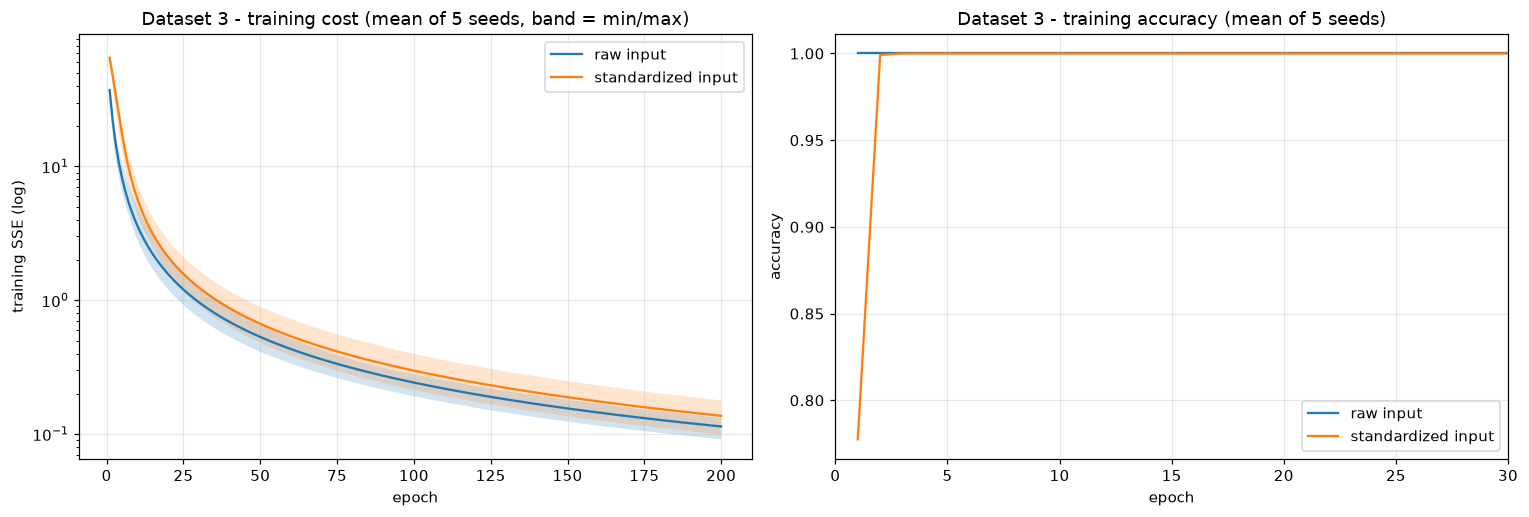

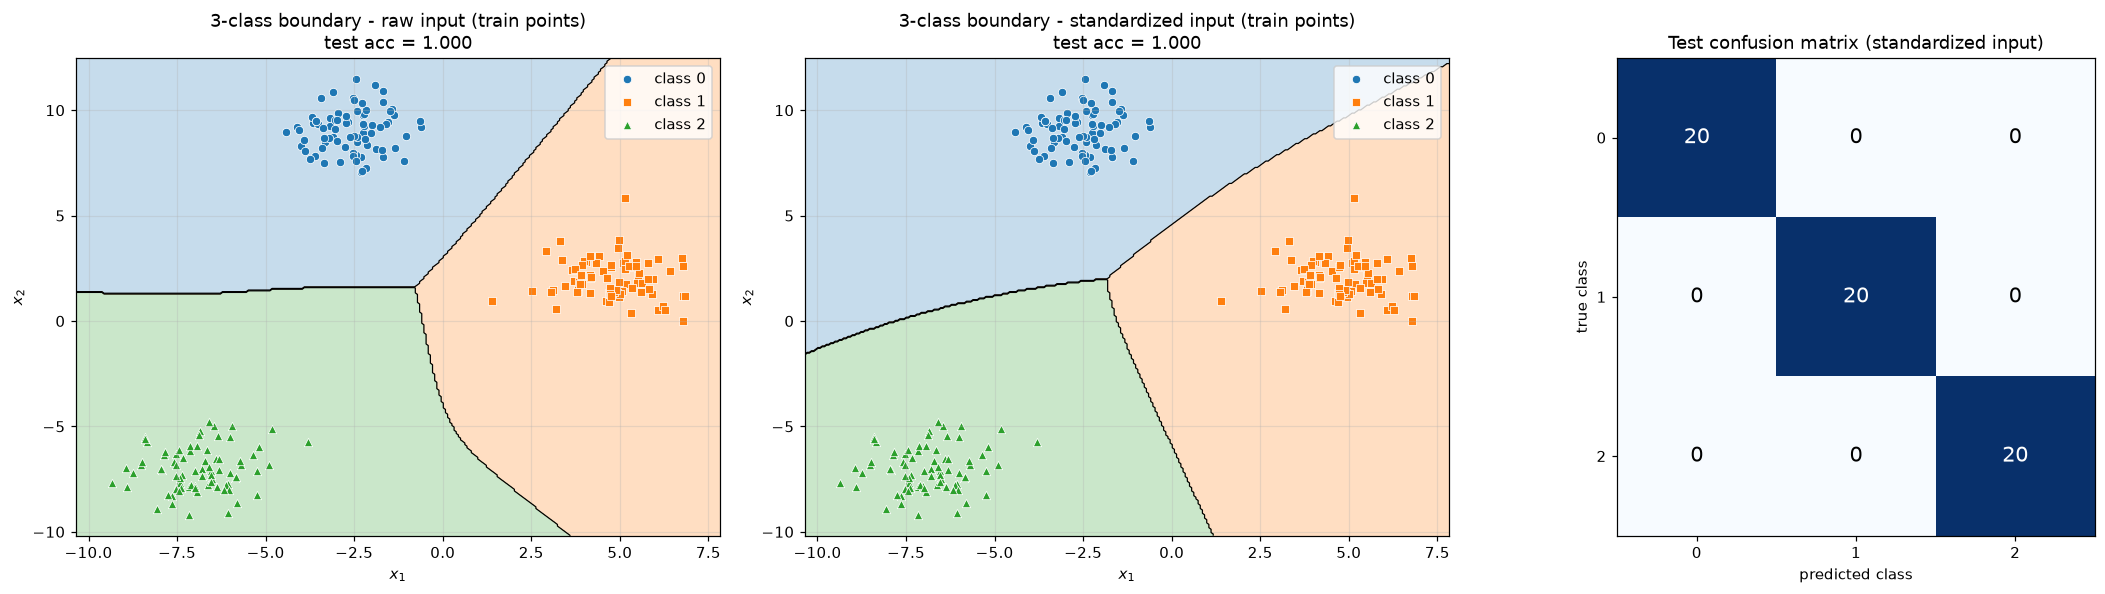

In [18]:
# Standardization statistics come from the training set only
train_mean, train_std = x3_train.mean(axis=0), x3_train.std(axis=0)
x3_train_std = (x3_train - train_mean) / train_std
x3_test_std = (x3_test - train_mean) / train_std
input_versions = {"raw": (x3_train, x3_test), "standardized": (x3_train_std, x3_test_std)}

MULTICLASS_CONFIG = dict(n_hidden=4, eta=0.1, epochs=200, scale=1.0, n_outputs=3)
MULTICLASS_SEEDS = range(5)

multiclass_runs = {}
for input_name, (x_train, x_test) in input_versions.items():
    multiclass_runs[input_name] = []
    for seed in MULTICLASS_SEEDS:
        W1, W2, cost_history, acc_history = train_mlp(x_train, y3_train, seed=seed, **MULTICLASS_CONFIG)
        multiclass_runs[input_name].append(dict(
            W1=W1, W2=W2, costs=cost_history, accs=acc_history,
            test_acc=accuracy_score(y3_test, predict_mlp(W1, W2, x_test))))
print("train mean:", train_mean, " train std:", train_std)

# Cost curves: mean over seeds with min-max band
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for input_name, runs in multiclass_runs.items():
    costs_per_seed = np.array([run["costs"] for run in runs])
    accs_per_seed = np.array([run["accs"] for run in runs])
    epoch_numbers = np.arange(1, costs_per_seed.shape[1] + 1)
    axes[0].plot(epoch_numbers, costs_per_seed.mean(0), label=f"{input_name} input")
    axes[0].fill_between(epoch_numbers, costs_per_seed.min(0), costs_per_seed.max(0), alpha=0.2)
    axes[1].plot(epoch_numbers, accs_per_seed.mean(0), label=f"{input_name} input")
axes[0].set(title="Dataset 3 - training cost (mean of 5 seeds, band = min/max)", xlabel="epoch",
            ylabel="training SSE (log)", yscale="log")
axes[1].set(title="Dataset 3 - training accuracy (mean of 5 seeds)", xlabel="epoch", ylabel="accuracy", xlim=(0, 30))
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.savefig("figures/stage5_cost_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# 3-class decision boundaries in the original input space (seed-0 models)
raw_model = multiclass_runs["raw"][0]
std_model = multiclass_runs["standardized"][0]
predictors = {
    "raw": lambda grid: predict_mlp(raw_model["W1"], raw_model["W2"], grid),
    "standardized": lambda grid: predict_mlp(std_model["W1"], std_model["W2"], (grid - train_mean) / train_std),
}
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, (input_name, predict_fn) in zip(axes, predictors.items()):
    plot_decision_boundary(predict_fn, x3_train, y3_train, f"3-class boundary - {input_name} input (train points)\n"
                           f"test acc = {multiclass_runs[input_name][0]['test_acc']:.3f}", ax, margin=1.0)

# Confusion matrix of the standardized model on the test set
test_confusion = confusion_matrix(y3_test, predictors["standardized"](x3_test))
axes[2].imshow(test_confusion, cmap="Blues")
for true_class in range(3):
    for predicted_class in range(3):
        count = test_confusion[true_class, predicted_class]
        axes[2].text(predicted_class, true_class, count, ha="center", va="center", fontsize=14,
                     color="white" if count > test_confusion.max() / 2 else "black")
axes[2].set(title="Test confusion matrix (standardized input)", xlabel="predicted class", ylabel="true class",
            xticks=range(3), yticks=range(3))
axes[2].grid(False)
plt.tight_layout()
plt.savefig("figures/stage5_boundaries_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

### Stage 5.2 — Results

In [19]:
def hidden_saturation(W1, x):
    hidden = sigmoid(add_bias(x) @ W1.T)
    return np.mean((hidden < 0.05) | (hidden > 0.95))


def epochs_to_full_accuracy(runs):
    """First epoch at which each run reaches 100% training accuracy."""
    return [int(np.argmax(run["accs"] == 1.0)) + 1 if run["accs"].max() == 1.0 else np.nan for run in runs]


print(f"{'input':<14}{'SSE ep.1':>16}{'SSE ep.10':>16}{'final SSE':>16}{'epochs to 100% train':>22}{'test acc':>16}{'sat. h (init)':>15}")
for input_name, runs in multiclass_runs.items():
    costs_per_seed = np.array([run["costs"] for run in runs])
    full_acc_epochs = epochs_to_full_accuracy(runs)
    test_accs = np.array([run["test_acc"] for run in runs])
    saturation = np.mean([hidden_saturation(init_weights(2, 4, 3, 1.0, np.random.default_rng(seed))[0],
                                            input_versions[input_name][0]) for seed in MULTICLASS_SEEDS])
    print(f"{input_name:<14}{costs_per_seed[:, 0].mean():>9.2f} ± {costs_per_seed[:, 0].std():<5.2f}"
          f"{costs_per_seed[:, 9].mean():>9.2f} ± {costs_per_seed[:, 9].std():<5.2f}"
          f"{costs_per_seed[:, -1].mean():>9.3f} ± {costs_per_seed[:, -1].std():<5.3f}"
          f"{np.mean(full_acc_epochs):>15.1f} ± {np.std(full_acc_epochs):<4.1f}"
          f"{test_accs.mean():>9.3f} ± {test_accs.std():<5.3f}{saturation:>10.3f}")

print("\nReported model (standardized input, seed 0)")
print("  test accuracy   :", std_model["test_acc"])
print("  confusion matrix:\n", test_confusion)

input                 SSE ep.1       SSE ep.10       final SSE  epochs to 100% train        test acc  sat. h (init)
raw               37.24 ± 3.98      3.61 ± 0.79     0.114 ± 0.014            1.0 ± 0.0     1.000 ± 0.000     0.685
standardized      64.87 ± 4.54      5.75 ± 1.21     0.137 ± 0.026            2.0 ± 0.6     1.000 ± 0.000     0.000

Reported model (standardized input, seed 0)
  test accuracy   : 1.0
  confusion matrix:
 [[20  0  0]
 [ 0 20  0]
 [ 0  0 20]]


**Interpretation:** see Stage 5 in `report/report.md`.

## Stage 6 — Ensemble of Networks
Dataset 2 with a **small network: 3 hidden units**, $\eta=0.1$, 200 epochs, $U[-1,1]$, trained with 10 different seeds (0–9).
Ensemble = average of the 10 networks' output values $\bar{y} = \frac{1}{10}\sum_m y_m$, class 1 if $\bar{y} \ge 0.5$.

### Stage 6.1 — Experiment

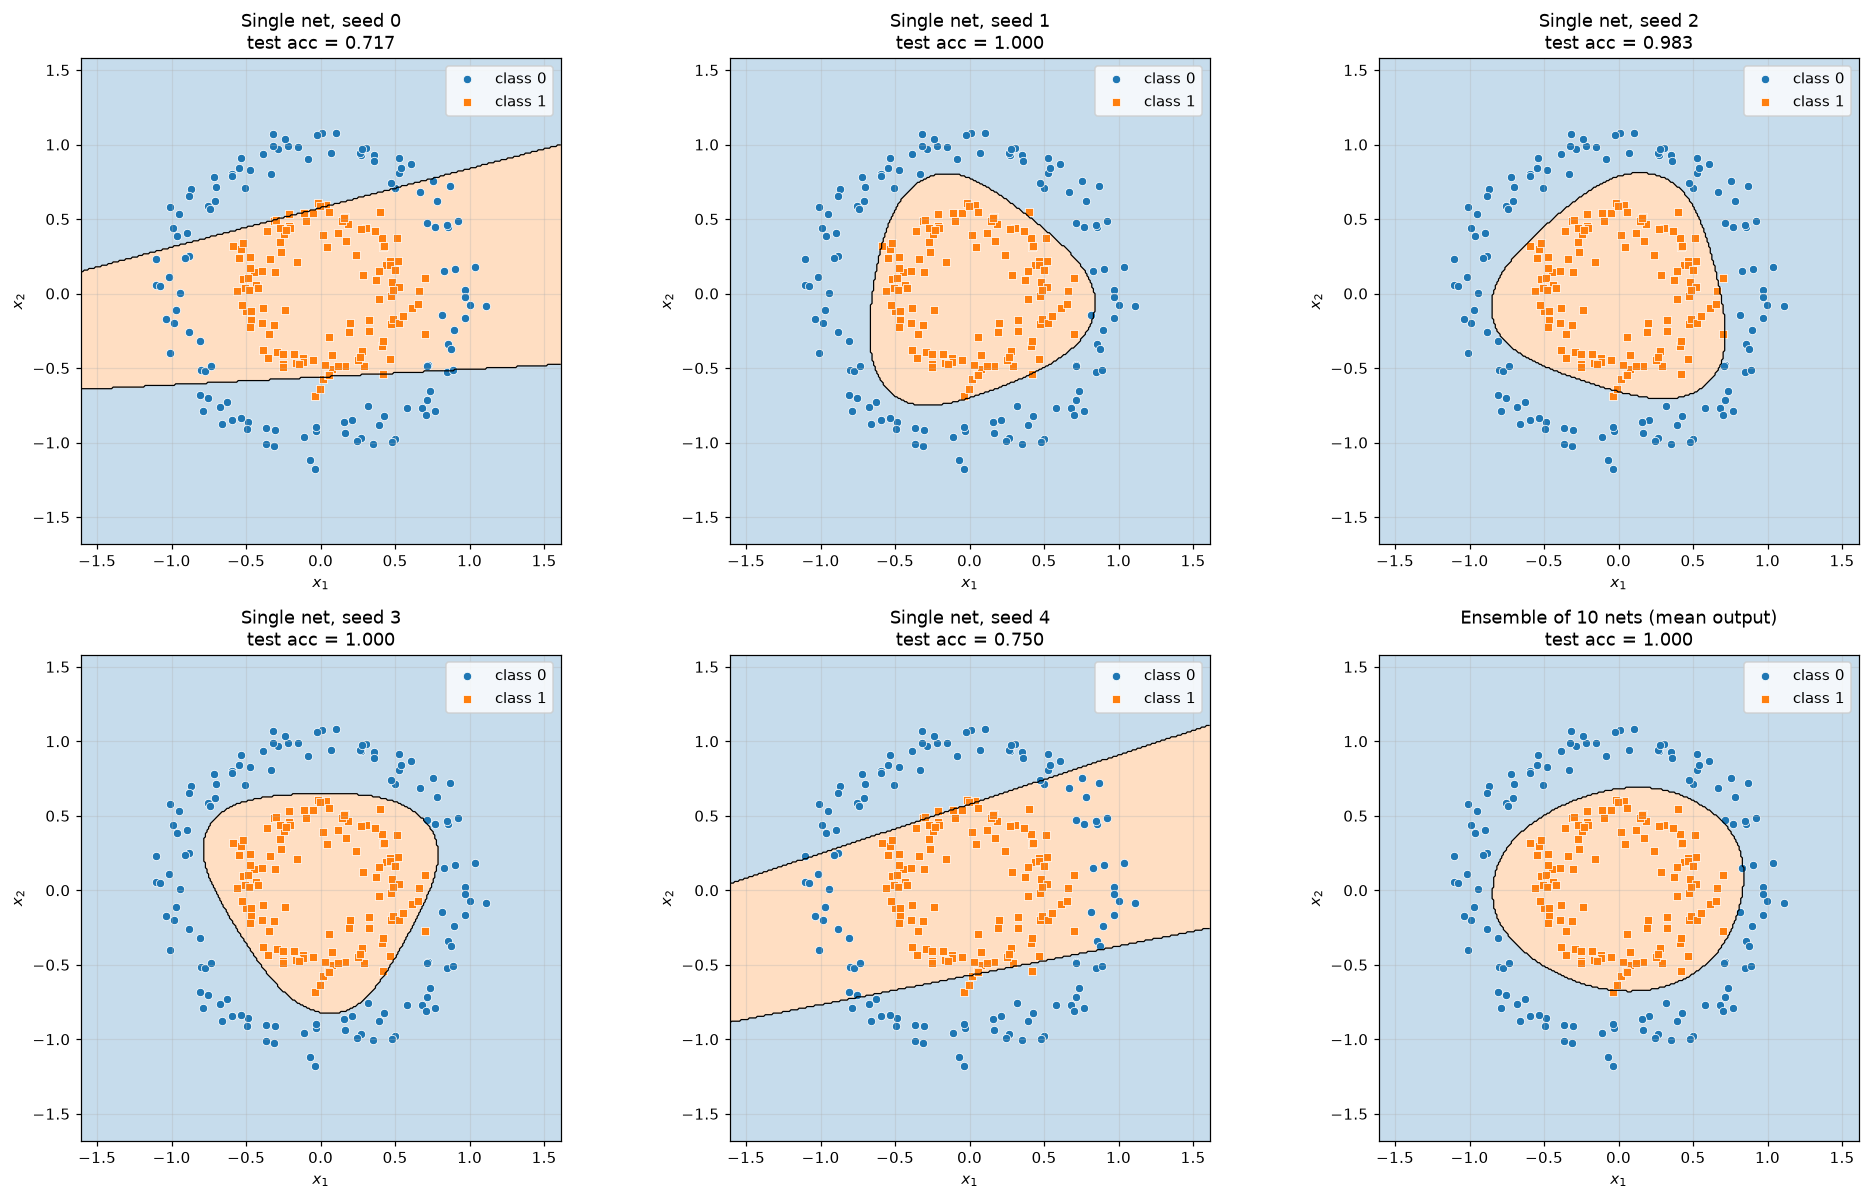

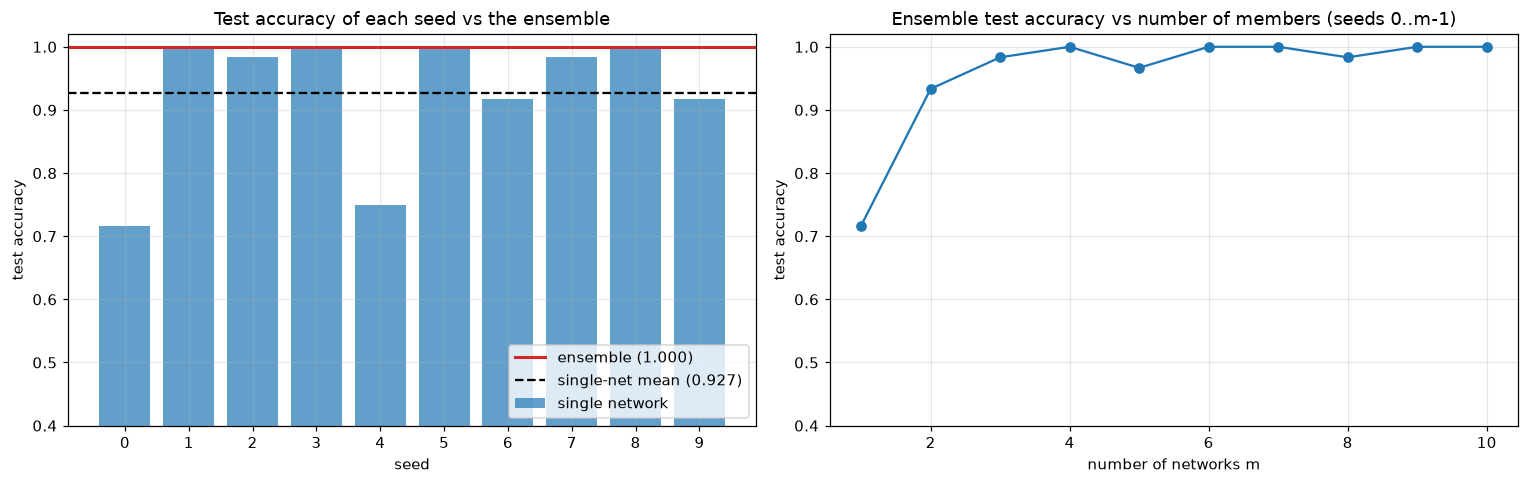

In [20]:
ENSEMBLE_CONFIG = dict(n_hidden=3, eta=0.1, epochs=200, scale=1.0)
ENSEMBLE_SEEDS = range(10)
ensemble_members = [run_mlp(seed=seed, **ENSEMBLE_CONFIG) for seed in ENSEMBLE_SEEDS]


def ensemble_output(networks, x):
    return np.mean([forward(net["W1"], net["W2"], x)[3][:, 0] for net in networks], axis=0)


def ensemble_predict(networks, x):
    return (ensemble_output(networks, x) >= 0.5).astype(int)


member_test_accs = np.array([member["test_acc"] for member in ensemble_members])
ensemble_test_acc = accuracy_score(y2_test, ensemble_predict(ensemble_members, x2_test))
ensemble_acc_by_size = [accuracy_score(y2_test, ensemble_predict(ensemble_members[:size], x2_test))
                        for size in range(1, 11)]

# Individual boundaries next to the ensemble boundary
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, member in zip(axes.ravel()[:5], ensemble_members[:5]):
    plot_decision_boundary(lambda grid, member=member: predict_mlp(member["W1"], member["W2"], grid),
                           x2_train, y2_train,
                           f"Single net, seed {member['config']['seed']}\ntest acc = {member['test_acc']:.3f}", ax)
plot_decision_boundary(lambda grid: ensemble_predict(ensemble_members, grid), x2_train, y2_train,
                       f"Ensemble of 10 nets (mean output)\ntest acc = {ensemble_test_acc:.3f}", axes[1, 2])
for ax in axes.ravel():
    ax.set_aspect("equal")
plt.tight_layout()
plt.savefig("figures/stage6_boundaries.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar([str(seed) for seed in ENSEMBLE_SEEDS], member_test_accs, color="tab:blue", alpha=0.7, label="single network")
axes[0].axhline(ensemble_test_acc, color="tab:red", lw=2, label=f"ensemble ({ensemble_test_acc:.3f})")
axes[0].axhline(member_test_accs.mean(), color="k", ls="--", label=f"single-net mean ({member_test_accs.mean():.3f})")
axes[0].set(title="Test accuracy of each seed vs the ensemble", xlabel="seed", ylabel="test accuracy", ylim=(0.4, 1.02))
axes[0].legend(loc="lower right")
axes[1].plot(range(1, 11), ensemble_acc_by_size, "o-")
axes[1].set(title="Ensemble test accuracy vs number of members (seeds 0..m-1)", xlabel="number of networks m",
            ylabel="test accuracy", ylim=(0.4, 1.02))
plt.tight_layout()
plt.savefig("figures/stage6_accuracy.png", dpi=150, bbox_inches="tight")
plt.show()

### Stage 6.2 — Results

In [21]:
print(f"{'seed':<6}{'final SSE':>10}{'train acc':>11}{'test acc':>10}")
for member in ensemble_members:
    print(f"{member['config']['seed']:<6}{member['costs'][-1]:>10.3f}{member['train_acc']:>11.3f}{member['test_acc']:>10.3f}")
print(f"\nSingle networks : test accuracy = {member_test_accs.mean():.4f} ± {member_test_accs.std():.4f}  "
      f"(min {member_test_accs.min():.3f}, max {member_test_accs.max():.3f})")
print(f"Ensemble (10)   : test accuracy = {ensemble_test_acc:.4f}")
print(f"Ensemble train accuracy = {accuracy_score(y2_train, ensemble_predict(ensemble_members, x2_train)):.4f}")
print("Ensemble accuracy vs size:", np.round(ensemble_acc_by_size, 3))

seed   final SSE  train acc  test acc
0         17.805      0.800     0.717
1          5.151      0.988     1.000
2          4.641      0.992     0.983
3          5.646      0.996     1.000
4         18.441      0.796     0.750
5          5.147      0.992     1.000
6          9.280      0.938     0.917
7          3.295      0.988     0.983
8          7.614      0.988     1.000
9         12.359      0.921     0.917

Single networks : test accuracy = 0.9267 ± 0.1017  (min 0.717, max 1.000)
Ensemble (10)   : test accuracy = 1.0000
Ensemble train accuracy = 0.9917
Ensemble accuracy vs size: [0.717 0.933 0.983 1.    0.967 1.    1.    0.983 1.    1.   ]


**Interpretation:** see Stage 6 in `report/report.md`.

## Bonus (a) — Boosting (AdaBoost-style)
Dataset 2, weak learner = a deliberately **weak 2-hidden-unit MLP** ($\eta=0.1$, 100 epochs, $U[-1,1]$). A single such network cannot draw a closed curve.
Networks are trained sequentially, 10 rounds (AdaBoost.M1 with resampling):
1. Draw a training set of the same size from the training data with probabilities $w_i$ (start uniform).
2. Train network $m$ on it, compute its weighted error on the full training set $\epsilon_m = \sum_{i \text{ misclassified}} w_i$ and its vote $\alpha_m = \tfrac12 \ln\frac{1-\epsilon_m}{\epsilon_m}$.
3. Increase the weights of misclassified samples: $w_i \leftarrow w_i\, e^{\alpha_m}$ (misclassified) or $w_i\, e^{-\alpha_m}$ (correct), then normalize.

Final prediction: class 1 if $\sum_m \alpha_m (2\hat{y}_m - 1) > 0$. For comparison, a plain average ensemble of 10 independent 2-hidden networks is also trained.

### Bonus (a).1 — Implementation and experiment

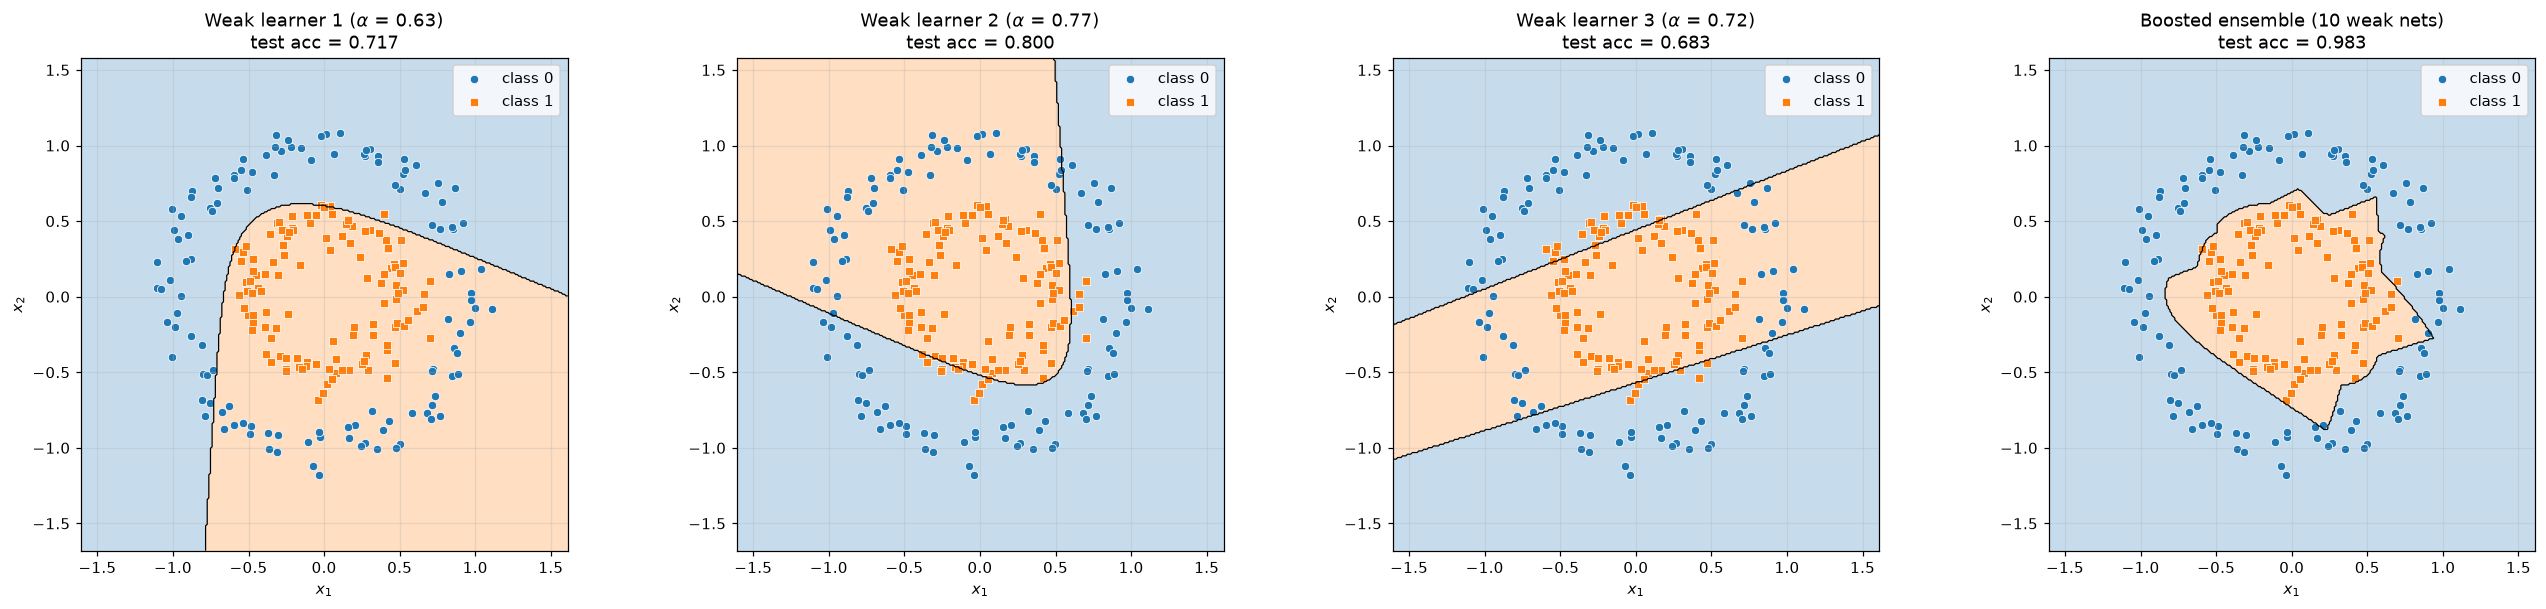

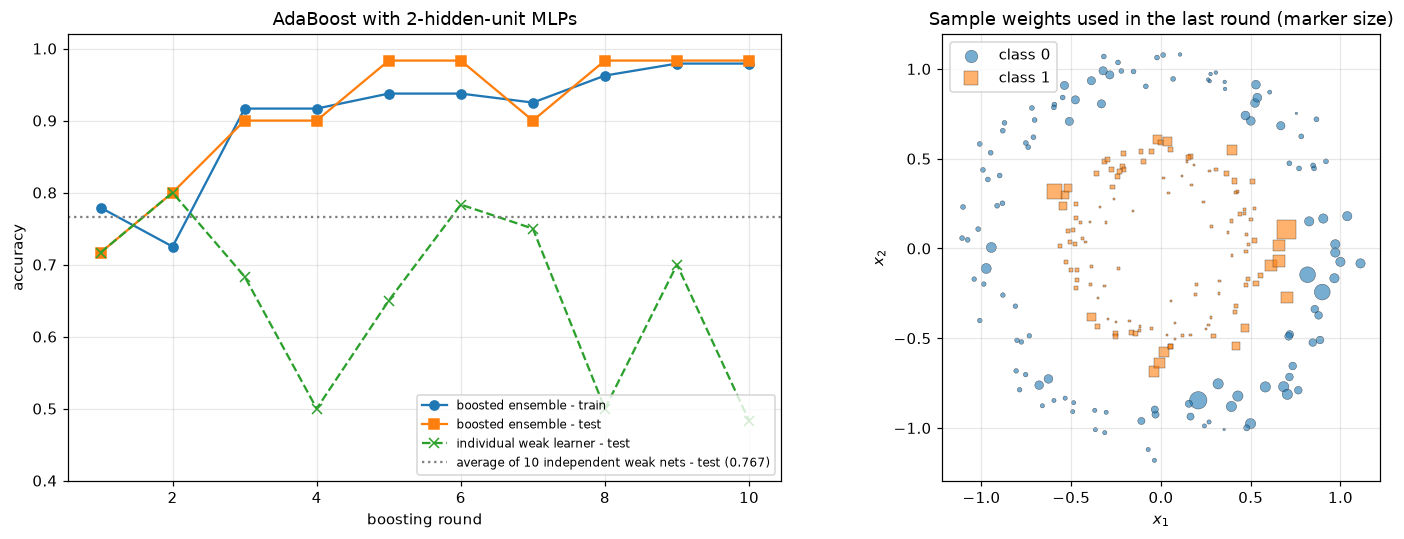

In [22]:
WEAK_LEARNER_CONFIG = dict(n_hidden=2, eta=0.1, epochs=100, scale=1.0)
N_ROUNDS = 10


def adaboost(x, y, n_rounds, seed=0):
    rng = np.random.default_rng(seed)
    sample_weights = np.full(len(x), 1 / len(x))
    learners, history = [], []
    for round_index in range(n_rounds):
        resampled = rng.choice(len(x), len(x), p=sample_weights)    # focus on high-weight samples
        W1, W2, _, _ = train_mlp(x[resampled], y[resampled], seed=round_index, **WEAK_LEARNER_CONFIG)
        misclassified = predict_mlp(W1, W2, x) != y
        weighted_error = np.clip(sample_weights[misclassified].sum(), 1e-10, 1 - 1e-10)
        alpha = 0.5 * np.log((1 - weighted_error) / weighted_error)
        learners.append((alpha, W1, W2))
        history.append((weighted_error, alpha, sample_weights.copy()))
        sample_weights = sample_weights * np.exp(np.where(misclassified, alpha, -alpha))
        sample_weights /= sample_weights.sum()
    return learners, history


def boosted_predict(learners, x):
    vote = sum(alpha * (2 * predict_mlp(W1, W2, x) - 1) for alpha, W1, W2 in learners)
    return (vote > 0).astype(int)


learners, boosting_history = adaboost(x2_train, y2_train, N_ROUNDS)
boosted_train_acc = [accuracy_score(y2_train, boosted_predict(learners[:m], x2_train)) for m in range(1, N_ROUNDS + 1)]
boosted_test_acc = [accuracy_score(y2_test, boosted_predict(learners[:m], x2_test)) for m in range(1, N_ROUNDS + 1)]
weak_learner_test_acc = [accuracy_score(y2_test, predict_mlp(W1, W2, x2_test)) for _, W1, W2 in learners]

# Baselines: one weak net on the full data, and a plain average of 10 independent weak nets
independent_weak_runs = [run_mlp(seed=seed, **WEAK_LEARNER_CONFIG) for seed in range(N_ROUNDS)]
averaged_weak_test_acc = accuracy_score(y2_test, ensemble_predict(independent_weak_runs, x2_test))

fig, axes = plt.subplots(1, 4, figsize=(24, 5.5))
for round_index, ax in enumerate(axes[:3]):
    alpha, W1, W2 = learners[round_index]
    plot_decision_boundary(lambda grid, W1=W1, W2=W2: predict_mlp(W1, W2, grid), x2_train, y2_train,
                           f"Weak learner {round_index + 1} ($\\alpha$ = {alpha:.2f})\n"
                           f"test acc = {weak_learner_test_acc[round_index]:.3f}", ax)
plot_decision_boundary(lambda grid: boosted_predict(learners, grid), x2_train, y2_train,
                       f"Boosted ensemble ({N_ROUNDS} weak nets)\ntest acc = {boosted_test_acc[-1]:.3f}", axes[3])
for ax in axes:
    ax.set_aspect("equal")
plt.tight_layout()
plt.savefig("figures/bonus_boosting_boundaries.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
round_numbers = np.arange(1, N_ROUNDS + 1)
axes[0].plot(round_numbers, boosted_train_acc, "o-", label="boosted ensemble - train")
axes[0].plot(round_numbers, boosted_test_acc, "s-", label="boosted ensemble - test")
axes[0].plot(round_numbers, weak_learner_test_acc, "x--", label="individual weak learner - test")
axes[0].axhline(averaged_weak_test_acc, color="gray", ls=":",
                label=f"average of 10 independent weak nets - test ({averaged_weak_test_acc:.3f})")
axes[0].set(title="AdaBoost with 2-hidden-unit MLPs", xlabel="boosting round", ylabel="accuracy", ylim=(0.4, 1.02))
axes[0].legend(fontsize=8, loc="lower right")
last_round_weights = boosting_history[-1][2]
for label in (0, 1):
    color, marker = CLASS_STYLE[label]
    in_class = y2_train == label
    axes[1].scatter(x2_train[in_class, 0], x2_train[in_class, 1], s=4000 * last_round_weights[in_class], c=color,
                    marker=marker, alpha=0.6, edgecolors="k", linewidths=0.3, label=f"class {label}")
axes[1].set(title="Sample weights used in the last round (marker size)", xlabel="$x_1$", ylabel="$x_2$")
axes[1].set_aspect("equal")
axes[1].legend()
plt.tight_layout()
plt.savefig("figures/bonus_boosting_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### Bonus (a).2 — Results

In [23]:
print(f"{'round':<7}{'weighted err':>13}{'alpha':>8}{'weak test acc':>15}{'ensemble train':>16}{'ensemble test':>15}")
for round_index, (weighted_error, alpha, _) in enumerate(boosting_history):
    print(f"{round_index + 1:<7}{weighted_error:>13.3f}{alpha:>8.3f}{weak_learner_test_acc[round_index]:>15.3f}"
          f"{boosted_train_acc[round_index]:>16.3f}{boosted_test_acc[round_index]:>15.3f}")
weak_single_test_accs = np.array([run["test_acc"] for run in independent_weak_runs])
print(f"\nSingle 2-hidden net (full data, 10 seeds) : test acc = {weak_single_test_accs.mean():.3f} ± {weak_single_test_accs.std():.3f}")
print(f"Average ensemble of those 10 nets         : test acc = {averaged_weak_test_acc:.3f}")
print(f"AdaBoost ensemble of 10 weak nets         : test acc = {boosted_test_acc[-1]:.3f}")

round   weighted err   alpha  weak test acc  ensemble train  ensemble test
1              0.221   0.630          0.717           0.779          0.717
2              0.176   0.770          0.800           0.725          0.800
3              0.192   0.719          0.683           0.917          0.900
4              0.343   0.325          0.500           0.917          0.900
5              0.358   0.292          0.650           0.938          0.983
6              0.260   0.524          0.783           0.938          0.983
7              0.145   0.887          0.750           0.925          0.900
8              0.256   0.533          0.500           0.963          0.983
9              0.259   0.526          0.700           0.979          0.983
10             0.395   0.213          0.483           0.979          0.983

Single 2-hidden net (full data, 10 seeds) : test acc = 0.623 ± 0.090
Average ensemble of those 10 nets         : test acc = 0.767
AdaBoost ensemble of 10 weak nets         : 

**Interpretation:** see Bonus (a) in `report/report.md`.

## Bonus (b) — Softmax + Cross-Entropy for the multi-class problem
Stage 5 (standardized input, same 4 hidden units, $\eta=0.1$, 200 epochs, seeds 0–4) with a **softmax output layer** and the cross-entropy loss
$E = -\sum_k d_k \ln y_k$. With this pair the output error signal simplifies to $\delta_o = d - y$ (verified by the gradient check in Stage 3.3).
The sigmoid + SSE runs are reused from Stage 5.

### Bonus (b).1 — Experiment

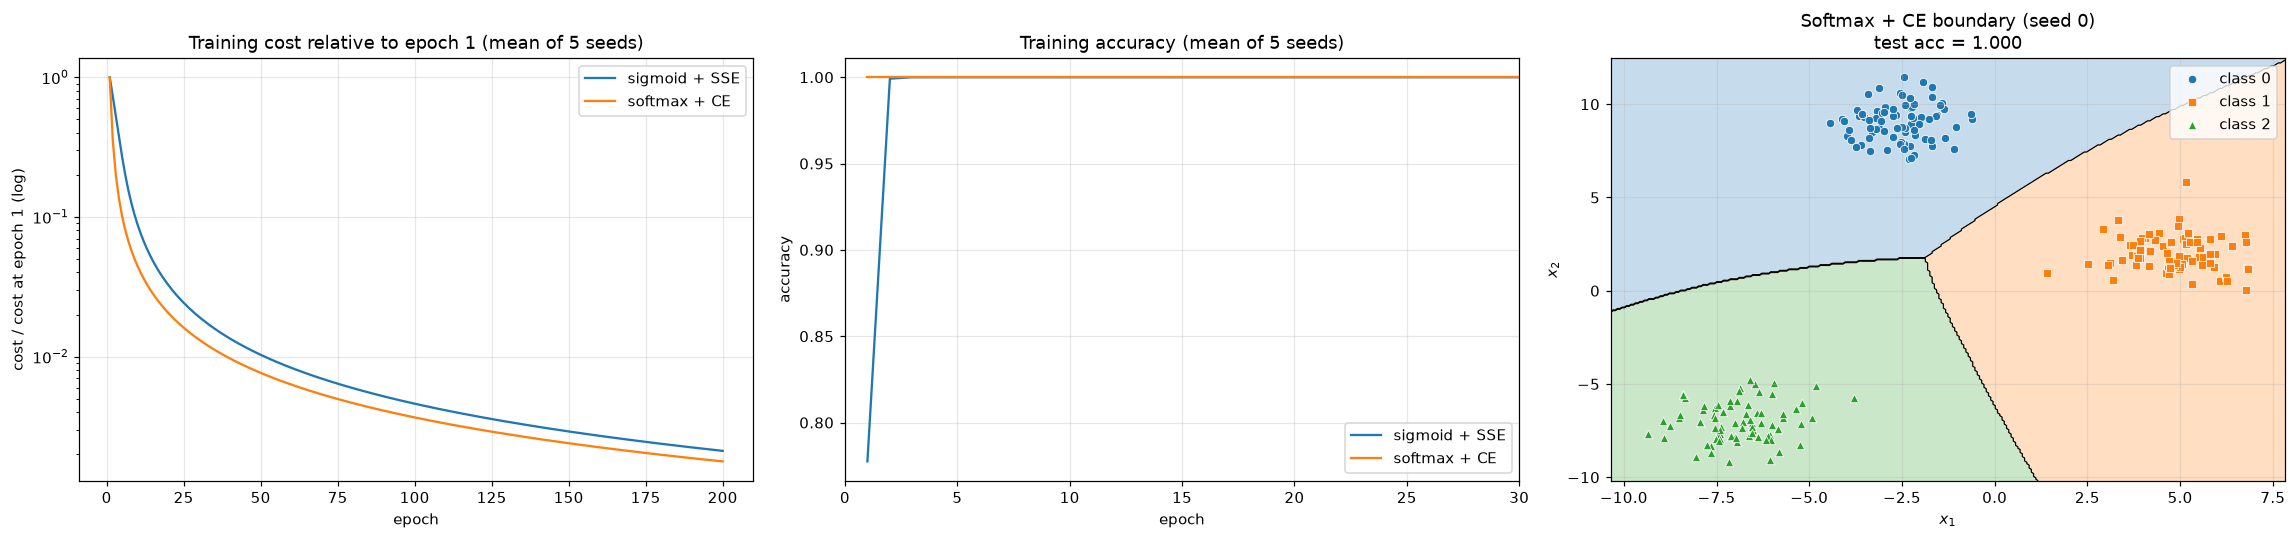

In [24]:
softmax_runs = []
for seed in MULTICLASS_SEEDS:
    W1, W2, cost_history, acc_history = train_mlp(x3_train_std, y3_train, seed=seed, output_type="softmax",
                                                  **MULTICLASS_CONFIG)
    softmax_runs.append(dict(W1=W1, W2=W2, costs=cost_history, accs=acc_history,
                             test_acc=accuracy_score(y3_test, predict_mlp(W1, W2, x3_test_std, "softmax"))))
output_comparison = {"sigmoid + SSE": multiclass_runs["standardized"], "softmax + CE": softmax_runs}

fig, axes = plt.subplots(1, 3, figsize=(21, 5))
for model_name, runs in output_comparison.items():
    costs_per_seed = np.array([run["costs"] for run in runs])
    accs_per_seed = np.array([run["accs"] for run in runs])
    epoch_numbers = np.arange(1, costs_per_seed.shape[1] + 1)
    mean_cost = costs_per_seed.mean(0)
    axes[0].plot(epoch_numbers, mean_cost / mean_cost[0], label=model_name)
    axes[1].plot(epoch_numbers, accs_per_seed.mean(0), label=model_name)
axes[0].set(title="Training cost relative to epoch 1 (mean of 5 seeds)", xlabel="epoch",
            ylabel="cost / cost at epoch 1 (log)", yscale="log")
axes[1].set(title="Training accuracy (mean of 5 seeds)", xlabel="epoch", ylabel="accuracy", xlim=(0, 30))
for ax in axes[:2]:
    ax.legend()
softmax_model = softmax_runs[0]
plot_decision_boundary(
    lambda grid: predict_mlp(softmax_model["W1"], softmax_model["W2"], (grid - train_mean) / train_std, "softmax"),
    x3_train, y3_train, f"Softmax + CE boundary (seed 0)\ntest acc = {softmax_model['test_acc']:.3f}", axes[2], margin=1.0)
plt.tight_layout()
plt.savefig("figures/bonus_softmax_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### Bonus (b).2 — Results

In [25]:
def mean_true_class_output(runs, output_type):
    """Average output value of the true class on the test set (how confident the network is)."""
    confidences = []
    for run in runs:
        output = forward(run["W1"], run["W2"], x3_test_std, output_type)[3]
        confidences.append(np.mean(output[np.arange(len(y3_test)), y3_test]))
    return np.mean(confidences)


print(f"{'model':<16}{'epochs to 100% train':>22}{'test acc':>16}{'mean true-class output (test)':>32}")
for model_name, runs in output_comparison.items():
    output_type = "softmax" if "softmax" in model_name else "sigmoid"
    full_acc_epochs = epochs_to_full_accuracy(runs)
    test_accs = np.array([run["test_acc"] for run in runs])
    print(f"{model_name:<16}{np.mean(full_acc_epochs):>15.1f} ± {np.std(full_acc_epochs):<4.1f}"
          f"{test_accs.mean():>9.3f} ± {test_accs.std():<5.3f}{mean_true_class_output(runs, output_type):>20.4f}")

softmax_output_sums = forward(softmax_model["W1"], softmax_model["W2"], x3_test_std, "softmax")[3].sum(axis=1)
sigmoid_output_sums = forward(std_model["W1"], std_model["W2"], x3_test_std)[3].sum(axis=1)
print("\nSoftmax outputs sum to 1 for every sample:", np.allclose(softmax_output_sums, 1))
print(f"Sigmoid outputs per sample sum to: min {sigmoid_output_sums.min():.3f}, max {sigmoid_output_sums.max():.3f}"
      " (not a probability distribution)")
print("Softmax confusion matrix (test):\n",
      confusion_matrix(y3_test, predict_mlp(softmax_model["W1"], softmax_model["W2"], x3_test_std, "softmax")))

model             epochs to 100% train        test acc   mean true-class output (test)
sigmoid + SSE               2.0 ± 0.6     1.000 ± 0.000              0.9782
softmax + CE                1.0 ± 0.0     1.000 ± 0.000              0.9995

Softmax outputs sum to 1 for every sample: True
Sigmoid outputs per sample sum to: min 0.995, max 1.025 (not a probability distribution)
Softmax confusion matrix (test):
 [[20  0  0]
 [ 0 20  0]
 [ 0  0 20]]


**Interpretation:** see Bonus (b) in `report/report.md`.